# 17 - Visualization Masterclass

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sambalshikhar/petrophys/blob/main/examples/part_b_advanced/17_visualization_masterclass.ipynb)

**Part B - Petrophys Curriculum**

`petrophys.visualization` is a full plotting suite, not a single `plot()` call. This
lesson is the **gallery**: we render every major figure type on real wells and briefly
explain what each is for and when to reach for it. Treat it as a visual index you can
return to when you need the right plot for a task.

In [1]:
# In Google Colab, this cell installs Petrophys (about a minute).
# Anywhere else it does nothing.
import sys

if "google.colab" in sys.modules:
    %pip install --quiet "petrophys[ml]"

## Learning goals

- Drive the **log plot** `pp.plot` with its built-in templates (`"auto"`,
  `"petrophysics"`, `"comprehensive"`, ...), and choose what it shows with `tracks=`,
  `curves=`, `curve_aliases=` and `curve_styles=`.
- Render the **triple combo** (`pp.triple_combo`) - the standard first-look display.
- Work through the **crossplot family** with one call, `pp.crossplot(data, x, y)`: the pair
  of curves picks neutron-density, Pickett, Hingle, M-N, MID, Buckles or flow units.
- Use the **specialist panels**: the flow units of real 30/6-5 core plugs and
  `pp.nmr_panel` on the bundled real Daydream 1 CMR; know what `pp.fmi_panel` needs
  (lesson 16 renders it on the real Daydream FMI).
- Show **zone flags** (`pp.zone_flags_plot`) and compare **several wells** in one figure
  (`pp.plot(wells, curves=...)`, `pp.histograms`, `pp.bar_chart`).

## Why this matters

Petrophysical interpretation is a visual discipline. The same numbers tell different
stories depending on the axes you put them on: a Pickett plot exposes the water line and
cementation exponent; an N-D crossplot separates lithology and gas; a Buckles plot tests
whether a zone follows constant bulk-volume water. Knowing which figure answers which question - and
letting the library build it from a template - is most of the craft.

### Prerequisites

Assumes the Part A workflow lessons (you should recognise `PHIE`, `SW`, `PERM`, and the
`NET_ROCK/NET_RES/NET_PAY` flags). We interpret two wells with `pp.interpret` partway
through so they carry a full interpreted curve set for the advanced figures.

In [2]:
import petrophys as pp
from petrophys.interpretation.core_analysis import core_data

### First, a plot with no interpretation

Reading and plotting are separate from interpretation. This LAS-only view needs no
external geology and no Rw.

The core water and oil saturation curves `SWC` and `SOC` of 30/6-5 are stored in
percent although the file labels them `frac`, so Petrophys divides them by 100 when
it standardizes the curves, and says so. The plot raises the note as a
`UserWarning` for both curves (printed under the cell), and the returned
`LogViewer` also records it in `viewer.warnings`, shown below the figure.
`pp.interpret` raises the same note. Keep these notes visible - a unit correction you
were not told about would be a silent change to your data. The `LogViewer` also
saves (`.save("well.png")`), closes (`.close()`) and lists its tracks
(`viewer.template.tracks`).

[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:855: UserWarning: SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)
[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:855: UserWarning: SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)


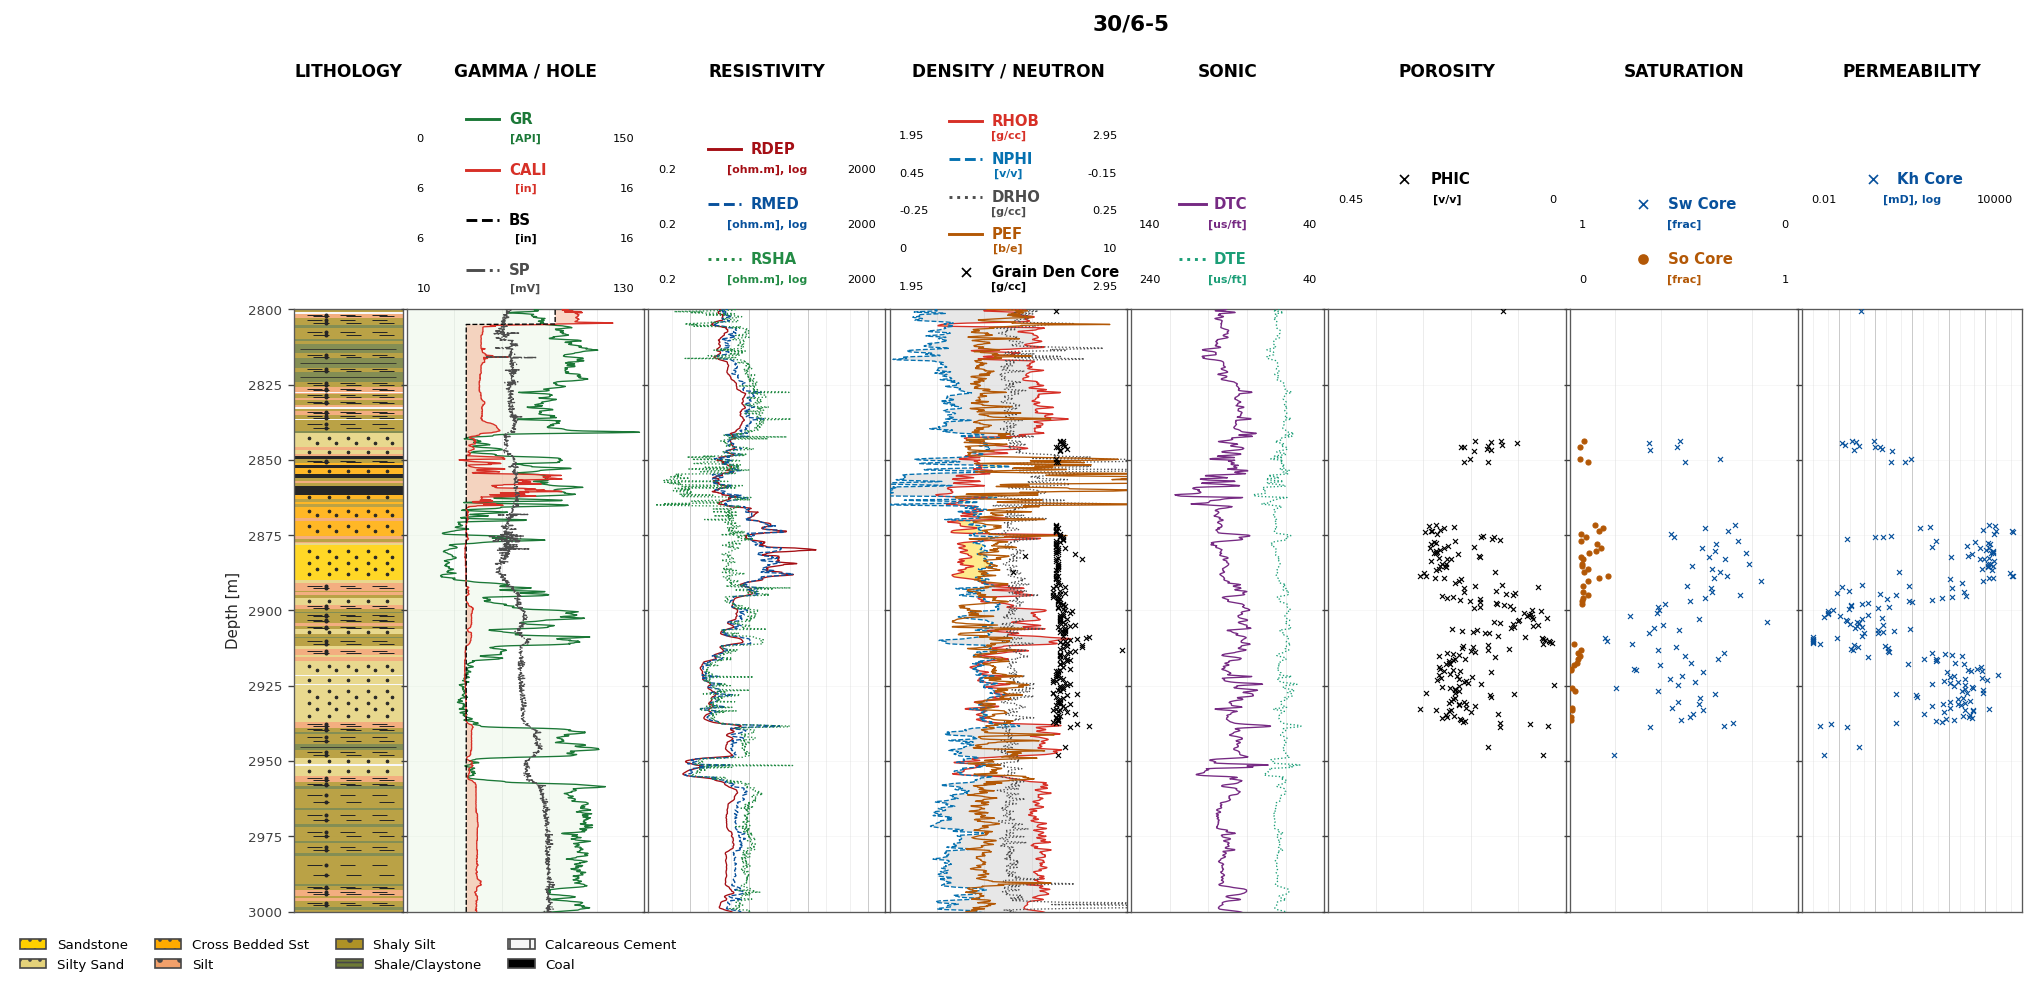

["SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.",
 "SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units."]

In [3]:
raw_geo = pp.read(pp.sample("30_6-5"))
viewer = pp.plot(raw_geo, top=2800, bottom=3000, figsize=(15, 8))
viewer.show()
viewer.warnings

### Optional external geology and selected tracks

Attach formations and lithology with `pp.read` for use by both plotting and later
interpretation: the plot marks the formation tops and fills the lithology track from
the intervals. Passing `formations=` or `lithology=` only to `pp.plot` affects that
plot, not the well's interpretation context.

[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:855: UserWarning: SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)
[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:855: UserWarning: SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)


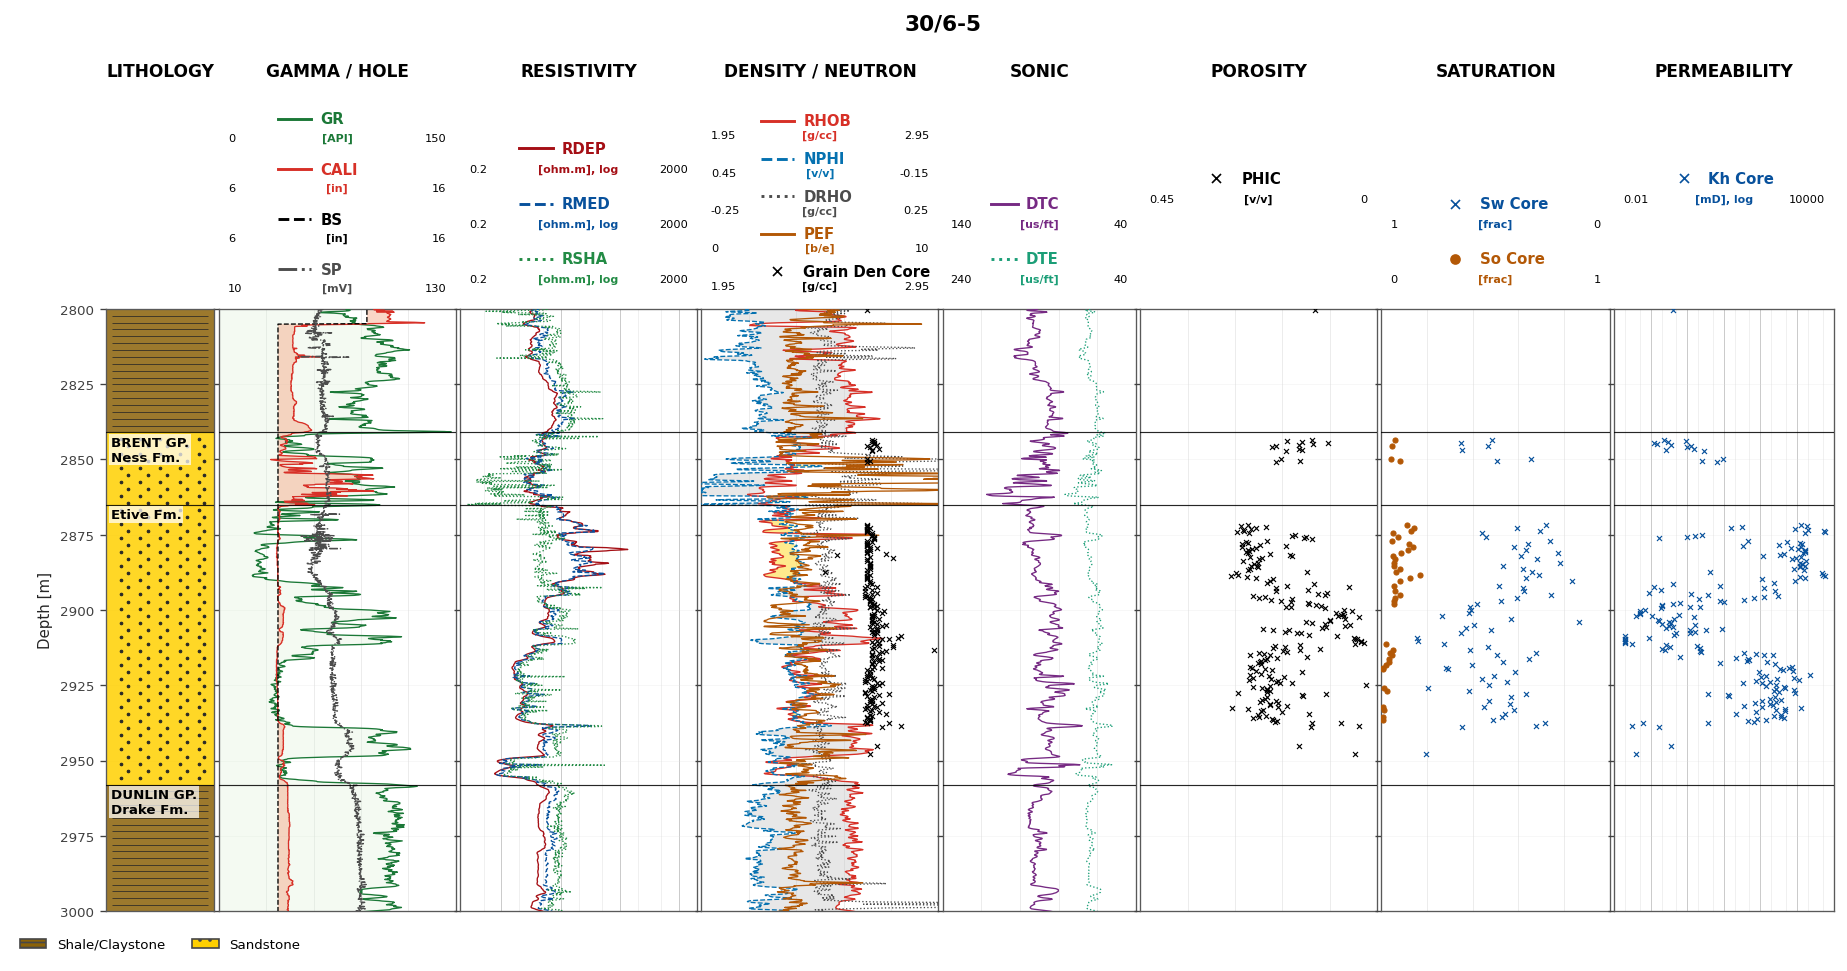

In [4]:
context_geo = pp.read(pp.sample("30_6-5"), formations=pp.sample("formations_30_6-5"),
                      lithology=pp.sample("lithology_30_6-5"))
pp.plot(context_geo, top=2800, bottom=3000, figsize=(15, 8)).show()

Track names select tracks, in the order you give them - here just porosity and
saturation. XML templates (`template_xml_path=`) remain the advanced interface for
whole layouts.

[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:855: UserWarning: SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)
[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:855: UserWarning: SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)


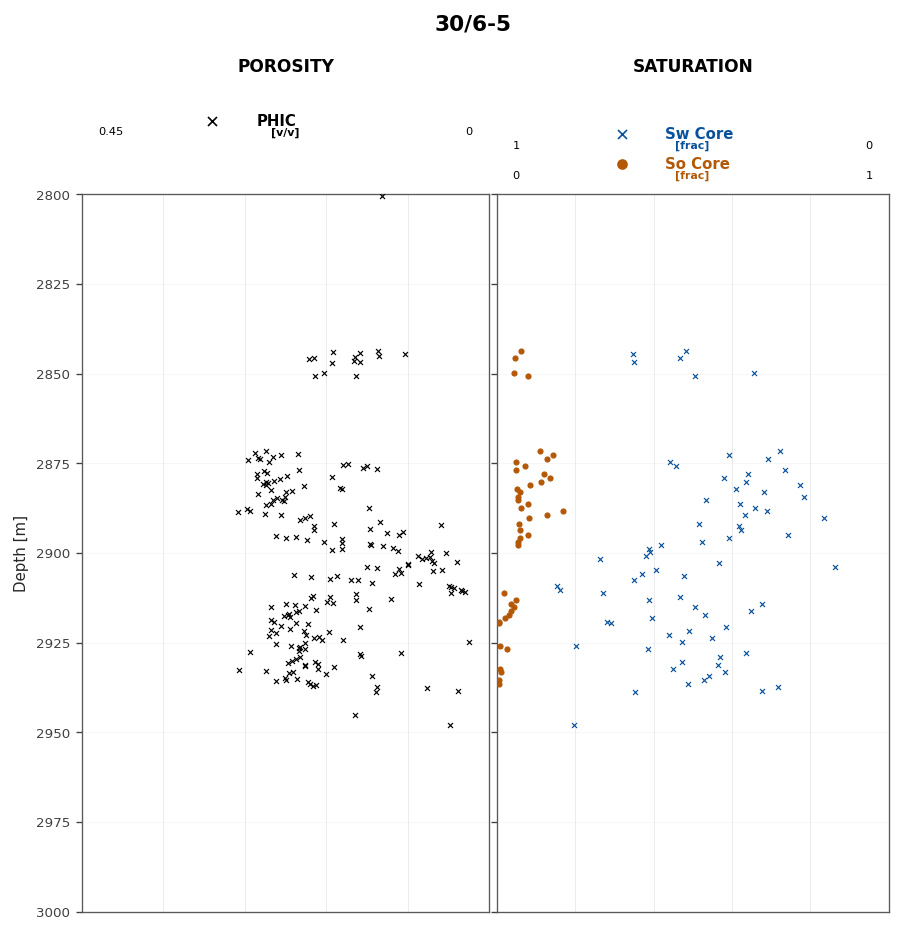

In [5]:
pp.plot(raw_geo, tracks=["POROSITY", "SATURATION"], top=2800, bottom=3000, figsize=(7, 8)).show()

### Plot only the curves you want

`curves=` keeps just the curves you name, each in its usual track; a curve no
track takes gets a generic track. Name them as the file does (`GR`, `DTE`) or by
their standard name (`GR`, `RDEP`, `NPHI`), whatever the file calls them.

[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:855: UserWarning: SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)
[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:855: UserWarning: SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)


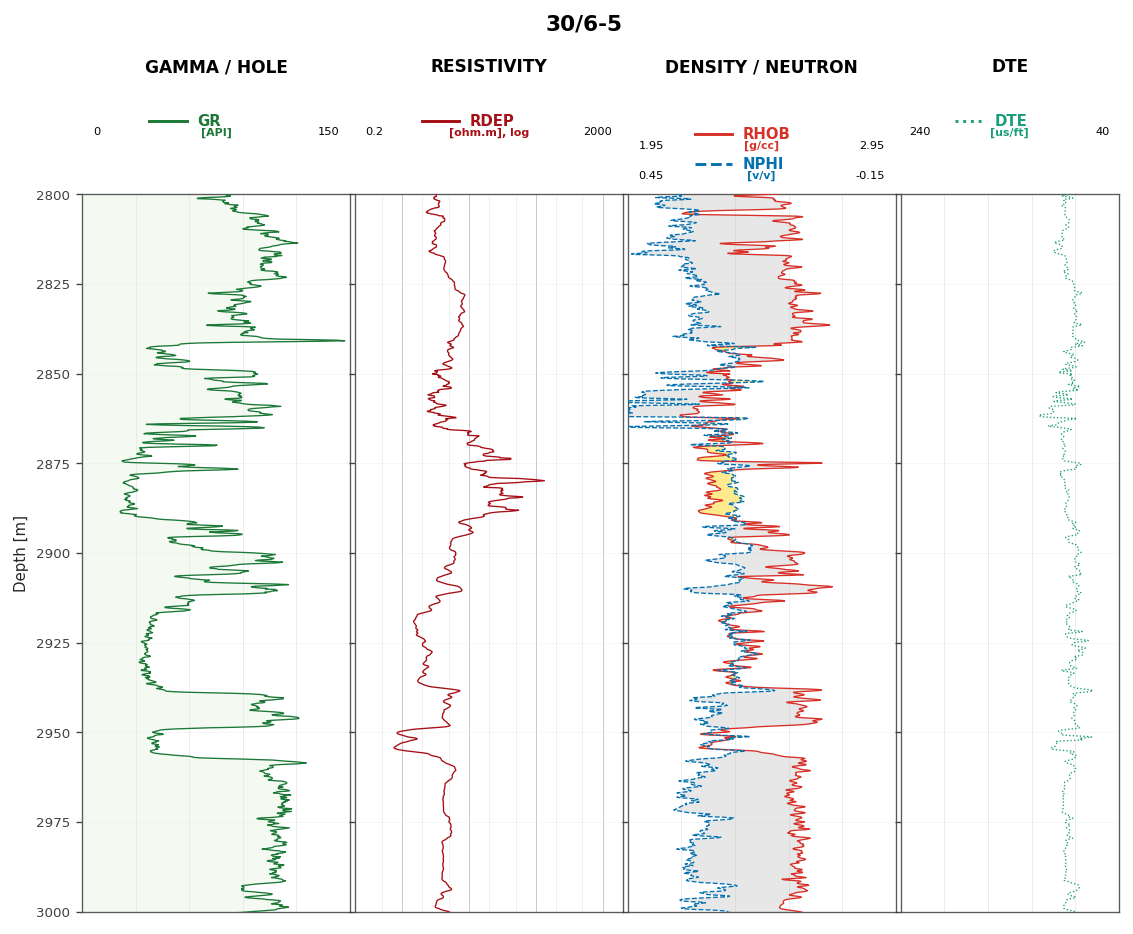

In [6]:
pp.plot(raw_geo, curves=["GR", "RDEP", "RHOB", "NPHI", "DTE"], top=2800, bottom=3000, figsize=(9, 8)).show()

The Teapot Dome well 44-MDX-10 is logged with company mnemonics: `GRD` for gamma ray,
`LLD`/`LLS` for the laterologs, `NPOR` for neutron porosity. The standard names find
them, and each track header names the curve it drew:

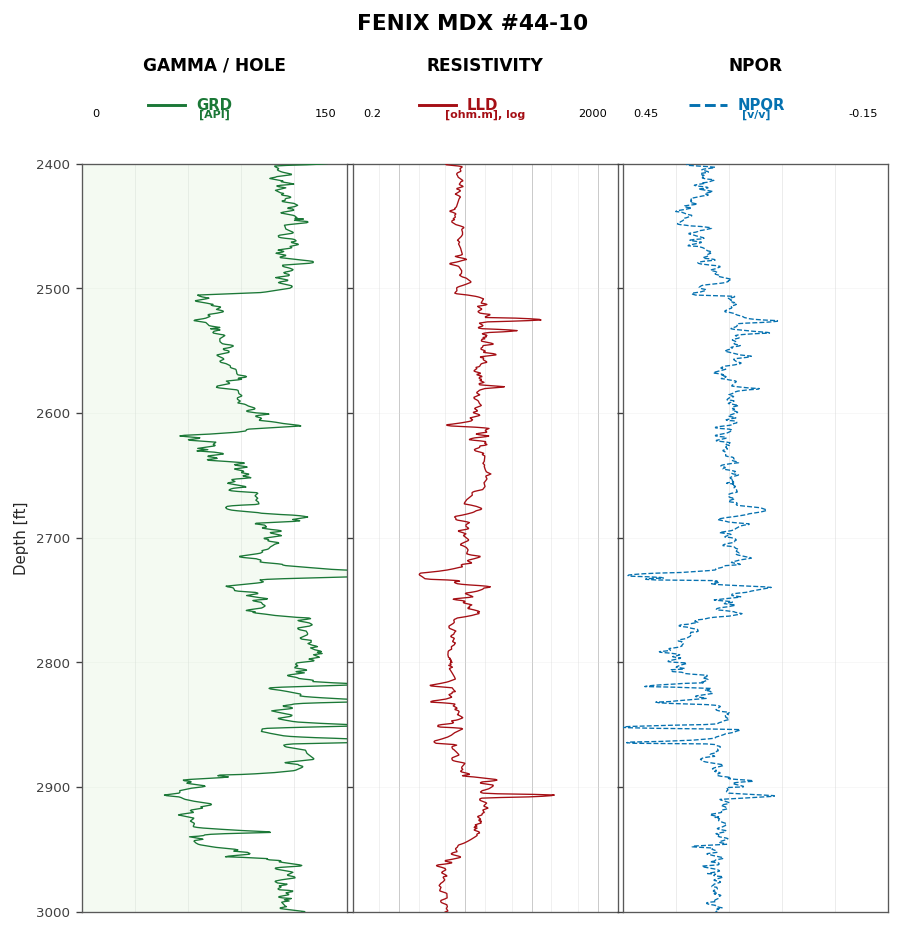

In [7]:
teapot = pp.read(pp.sample("teapot_44-mdx-10"))
pp.plot(teapot, curves=["GR", "RDEP", "NPHI"], top=2400, bottom=3000, figsize=(7, 8)).show()

### Your own curve names

No alias table holds every company's names. The same file records its spontaneous
potential as `SPR` (header: SPONTANEOUS POTENTIAL FROM R), which no table maps, so the
automatic layout puts it in a generic `OTHER` track. A curve-name mapping tells
Petrophys what it is, and `SPR` joins the gamma-ray track as SP:

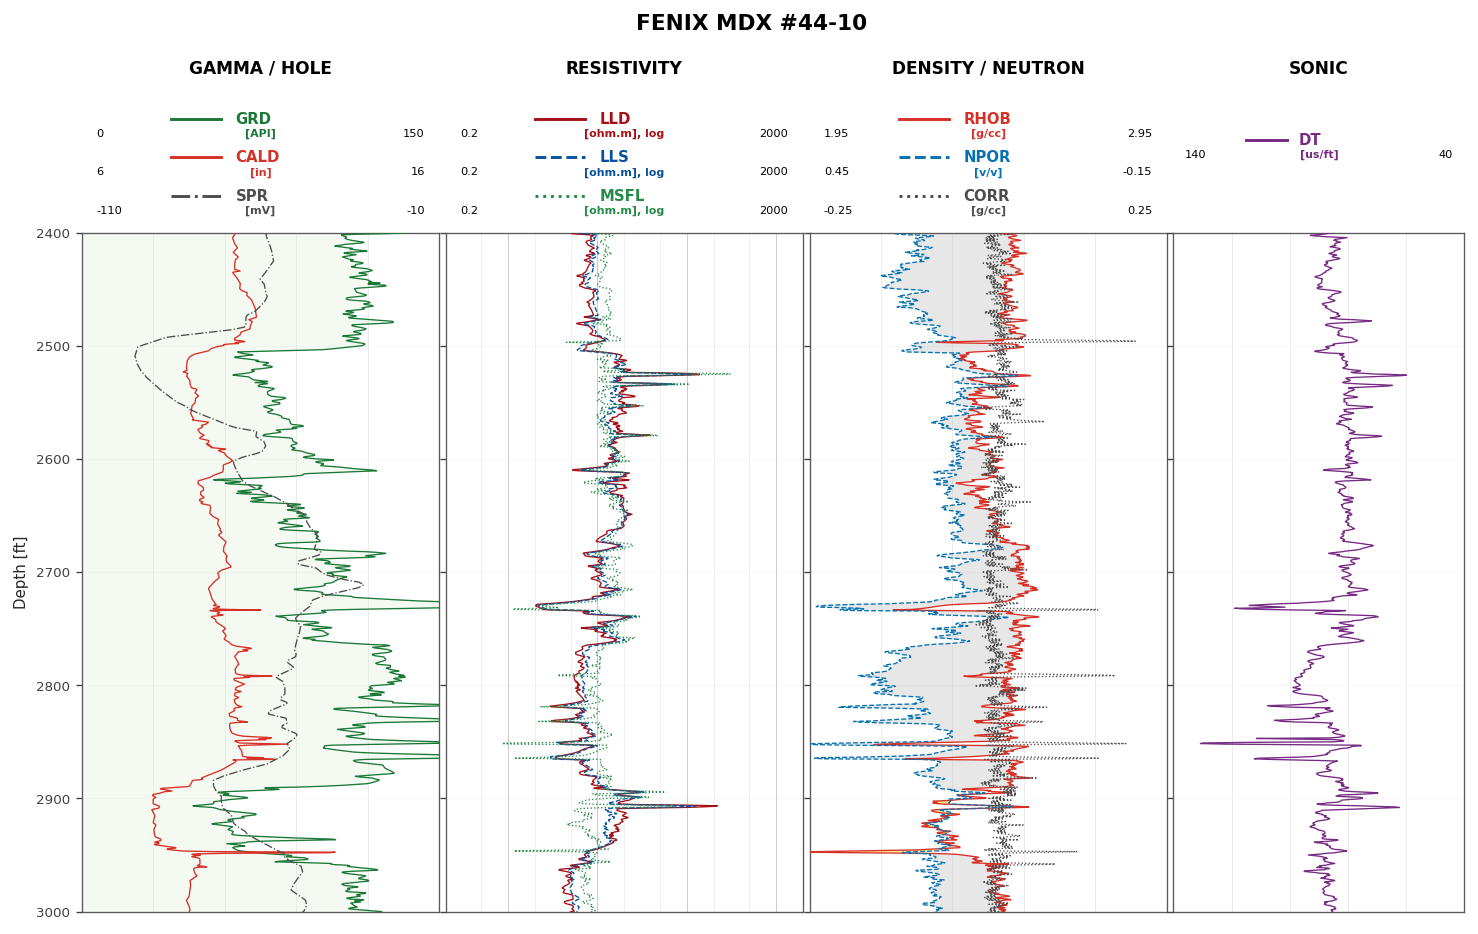

In [8]:
pp.plot(teapot, curve_aliases={"SPR": "SP"}, top=2400, bottom=3000, figsize=(12, 8)).show()

The mapping is a dict, or a CSV/Excel table with `curve` and `standard` columns, so one
file serves every well that uses those names. Give it to `pp.read`
(`pp.read(path, curve_aliases="company_curve_names.csv")`) and it is stored on the
well, so plotting and `pp.interpret` both use it; `pp.plot(..., curve_aliases=...)`
applies it to one plot. A mapping to a name the library does not know is refused with
the list of standard names, rather than guessed.

### Restyle a curve

`curve_styles=` changes one curve's colour, scale, line, fill or marker without an XML
template, by the file's name or the standard name:

[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:855: UserWarning: SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)
[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:855: UserWarning: SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)


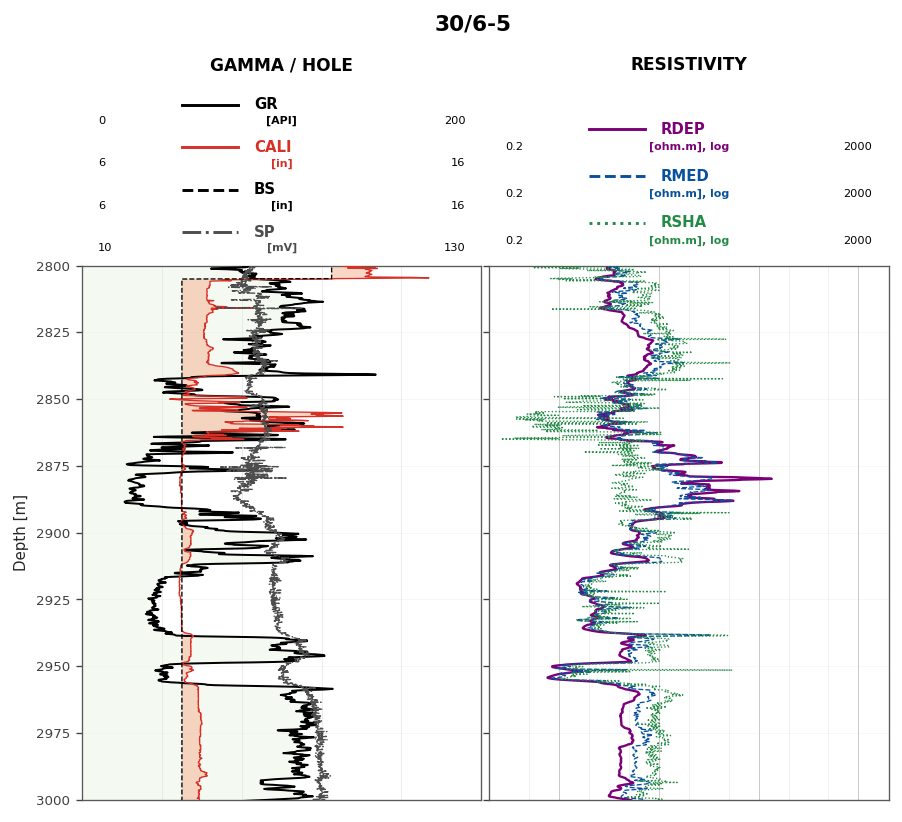

In [9]:
pp.plot(raw_geo, tracks=["GAMMA / HOLE", "RESISTIVITY"], top=2800, bottom=3000, figsize=(7, 7),
        curve_styles={"GR": {"color": "black", "right": 200, "line_width": 1.2},
                      "RDEP": {"color": "#7a0177", "line_width": 1.4}}).show()

### Interpret the teaching wells for the advanced figures

The remaining panels use calculated products. Each single-well run uses `pp.interpret`;
batch processing is covered separately in lesson 18.

- **30/6-5**: we pass the study value Rw = 0.070 ohm.m *measured at 230 degF*
  (`rw=0.070, rw_meas_temp="230 degF"`), a teaching-study assumption. We also pass the
  bundled formation tops (`formations=`): with them the workflow fits the core
  calibration (`PHIE_CC`, `PERM_CC`) per formation where a formation has enough
  plugs, and the tables agree with lessons 10, 11 and 21. Without the
  temperature the library would take Rw at the median formation temperature, which
  changes saturation strongly. The run's warnings are shown below the cell: the
  lithology step set the PEF aside (see section 1), and the bad-hole flag removed
  net pay where it marks the hole as bad.

In [10]:
geo_result = pp.interpret(raw_geo, formations=pp.sample("formations_30_6-5"), rw=0.070, rw_meas_temp="230.0 degF")   # Rw (ohm.m) at 230 degF
geo_result.warnings

[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:855: UserWarning: SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)
[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:855: UserWarning: SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)


['lithology: PEF set aside: in 94% of 331 clean porous samples the apparent matrix density is quartz-like (< 2.67 g/cm3) but the apparent matrix U calcite-like (> 10 b/cm3), the signature of barite-weighted mud; minerals solved without PEF',
 "Bad hole removed 107.25 m of net pay (BAD_HOLE at 12631 of 22176 samples). Check the flag against the caliper and DRHO; bad_hole={'drho': ..., 'cali': ...} sets its thresholds and skip_steps=['bad_hole'] keeps the pay.",
 "The LAS header gives rw_meas_temp=(230.0, 'degF'); not used, rw_meas_temp='230.0 degF' is set"]

- **HW-3** (a Costa carbonate well whose LAS covers only the Kharaib-2 reservoir
  interval): no Rw is passed. The LAS header carries Rw and the temperature it was
  measured at, and the workflow corrects that value to formation temperature
  (`carb_result.print_trace()` shows the decision in its `rw` step).
  We pass `lithology="carbonate"` because the lithology domain defaults to
  `clastic`, which would interpret this carbonate with a sandstone matrix.
  Inside the carbonate domain the workflow picks the matrix itself: the second
  warning says it resolved **limestone** (by `multi_mineral_solver`). The file has no
  core porosity, so the run keeps the file's own `PHIE_CC` / `PERM_CC` curves and, as
  the first warning says, uses them as they stand for SW, BVW, net pay and RQI.

Neither the figures nor a successful run prove that every scientific assumption is
appropriate for another well.

In [11]:
carb_result = pp.interpret(pp.read(pp.sample("HW-3")), lithology="carbonate")   # Rw from the LAS header
carb_result.warnings

['Input curves PHIE_CC, PERM_CC are used as they stand by every step (SW, BVW, net pay, RQI): the well has no core porosity and no peer-well core to fit its own core model.',
 "RHOB lines up with NPHI 55 ft higher than recorded (correlation -0.79, against 0.11 as recorded): the density may be off depth, and porosity from it describes other beds. find_log_depth_shift(well, 'RHOB', 'NPHI') and shift_curves(...) check and move it before interpreting.",
 'Auto lithology resolved via multi_mineral_solver (100% of 410 samples): matrix_type=limestone',
 'No clean porous rock reads as water at the Rw in use: over its clean porous rock (VCL < 0.3, porosity > 0.05, 387 samples) even the 5th percentile of the apparent water resistivity Rwa = Rt x phi^m / a is 32.25 times it (median 101.14), so Archie gives Sw below 0.18 at 95% of those samples. Rwa equals Rw in water-bearing rock, so either that rock holds hydrocarbon throughout, or the formation water is fresher than this Rw implies, or a and m 

#### What the HW-3 defaults produce

Compare the workflow's own porosity and permeability (`PHIE`, `PERM`) with the
core-corrected curves delivered in the same LAS file (`PHIE_CC`, `PERM_CC`), which
the interpreted well carries unchanged:

In [12]:
carb_result.well.to_dataframe(curves=["PHIE", "PHIE_CC", "PERM", "PERM_CC"], include_depth=False).describe().round(3)

,PHIE,PHIE_CC,PERM,PERM_CC
count,431.000,351.000,431.000,355.000
mean,0.198,0.244,2115.163,33.506
std,0.061,0.095,2010.601,97.437
min,0.032,0.000,0.002,0.010
25%,0.174,0.230,428.765,5.150
50%,0.216,0.290,1669.801,7.300
75%,0.246,0.300,3670.432,19.000
max,0.310,0.330,10000.000,990.000


The run's `PHIE` reads below the file's core-corrected porosity (median 0.216
against 0.290), and its permeability is far from the file's `PERM_CC`: a median
of about 1,670 mD against 7.3 mD. The default carbonate route uses a Coates-type
transform with an irreducible saturation taken from the low end of the computed
Sw, and clips it at 10,000 mD (the maximum above). That permeability is
**uncalibrated** and should not be read as a property of the rock. The figures
below still use it, to show the plot types; where it appears (the HW-3
permeability track and the Buckles colour scale), read it as uncalibrated output.
For a study, use the file's `PERM_CC` (the workflow carries it unchanged and uses
it for RQI) or calibrate the permeability transform to core.

## 1. Template log viewer

`pp.plot` builds a multi-track figure from a PetroPy-style **XML template**. Choose a
built-in layout with `template=`: `"auto"` (the default) builds tracks from the curves
present; `"raw"`, `"petrophysics"`, `"minerals"` and `"comprehensive"` are fixed
layouts. Passing the interpretation **result** plots the interpreted well with its
calculated curves. Curves a fixed template asks for but the well lacks are skipped and
listed in `viewer.warnings`.

The `"comprehensive"` layout below shows everything the interpretation produced over
the Heather shale and the Brent Group sands.

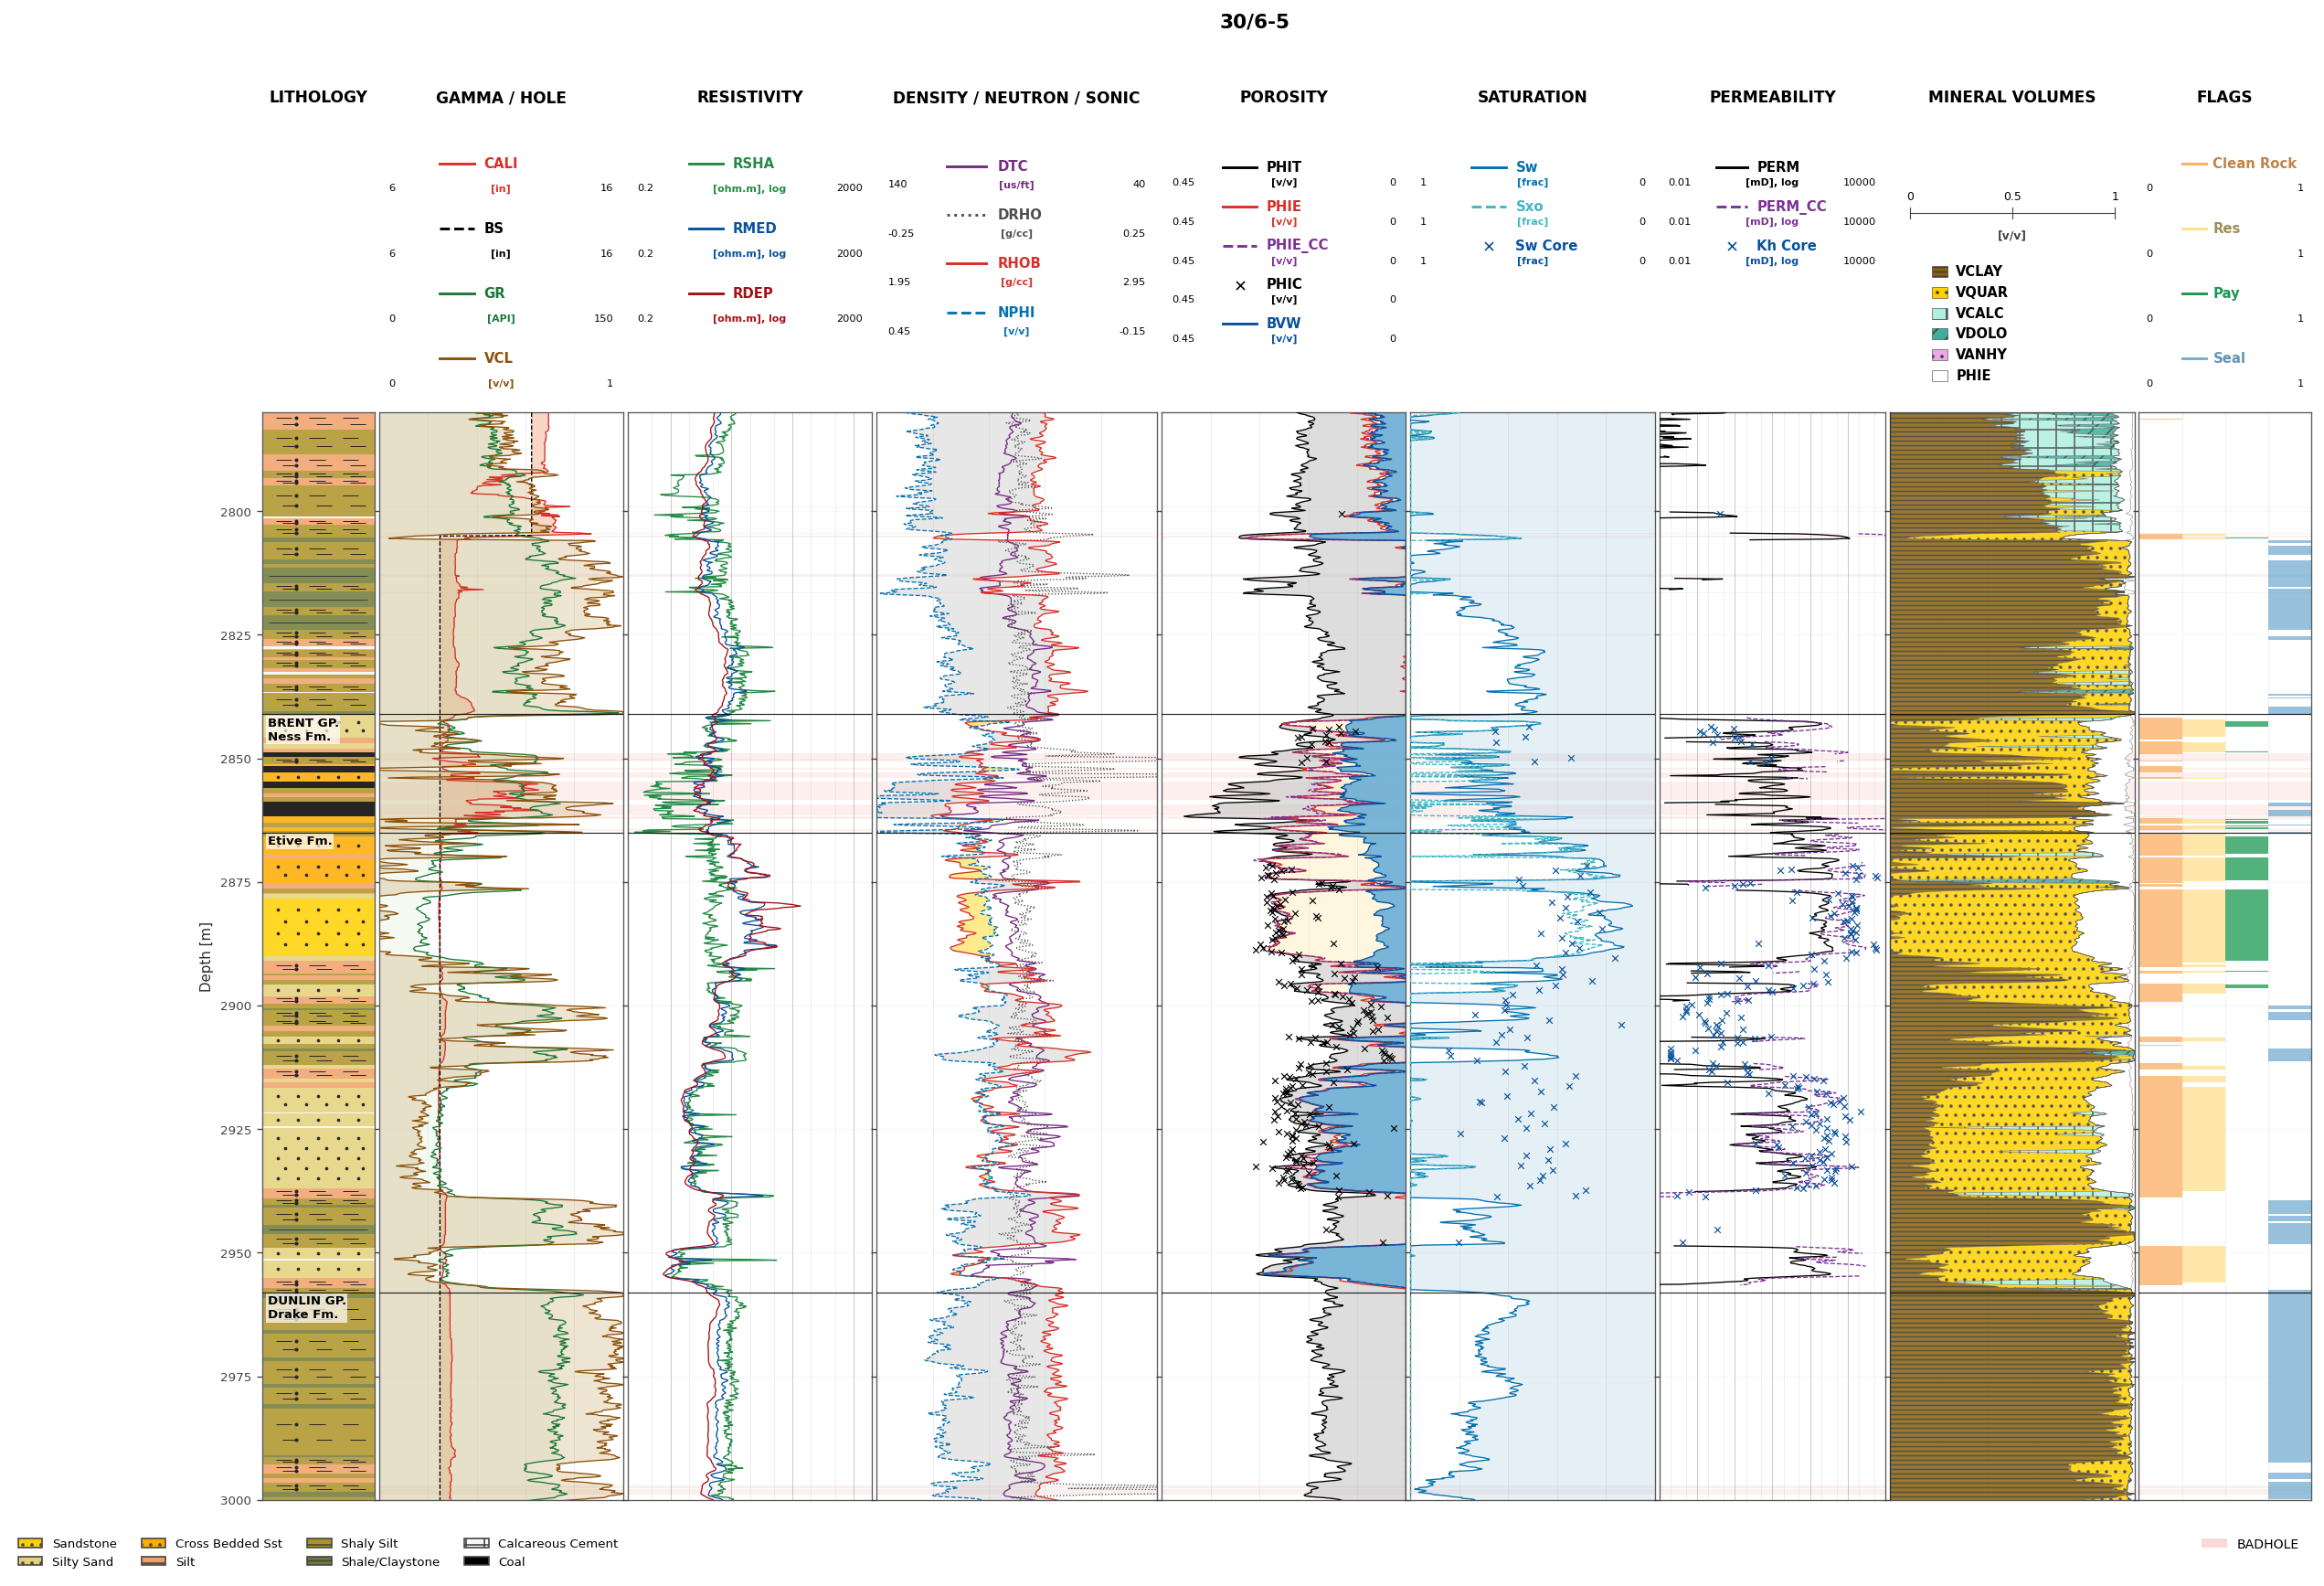

In [13]:
pp.plot(geo_result, template="comprehensive", top=2780, bottom=3000).show()

**Check the PEF before reading the MINERAL VOLUMES track.** In the DENSITY / NEUTRON
track of the first plot in this lesson, the PEF (orange, 0-10 b/e) of the clean Etive
sand (about 2865-2958 m) reads around 4-5 b/e, close to calcite (5.08) and far from
quartz (1.81), and the overlying Heather shale reads nearly as high. The whole PEF run is shifted upward, as it is when the mud is weighted
with barite, while the lithology labels and core grain densities of 2.66-2.67 g/cm3
describe quartz sandstone with only thin calcite-cemented streaks. A multi-mineral
solver that trusts this PEF turns quartz into calcite. `pp.interpret` recognises the
signature, quartz-like apparent matrix density with calcite-like apparent matrix U in
most clean porous samples, and solves the minerals without PEF, saying so in its first
warning (shown after the interpretation above); the Brent Group sands come out as
quartz in the MINERAL VOLUMES track. On another well, check PEF against a known clean
sand the same way.

### The adaptive `auto` template

The default `template="auto"` inspects the curves actually present and assembles tracks
on the fly (gamma/hole, resistivity, density-neutron, porosity, saturation,
permeability, flags, ...), skipping any family the well lacks. This is the safe default
for an unknown LAS. Logged curves no named track takes go to generic `OTHER` tracks;
interpretation intermediates (`VCL_GR`, `PHI_SEC`, flags drawn as shading) and exact
copies of a drawn curve stay out. The computed temperature profile and Rw/Rmf tracks
are optional: `viewer.diagnostics["optional_tracks"]` lists them (shown below the
figure), and they are drawn when `tracks=` names them.

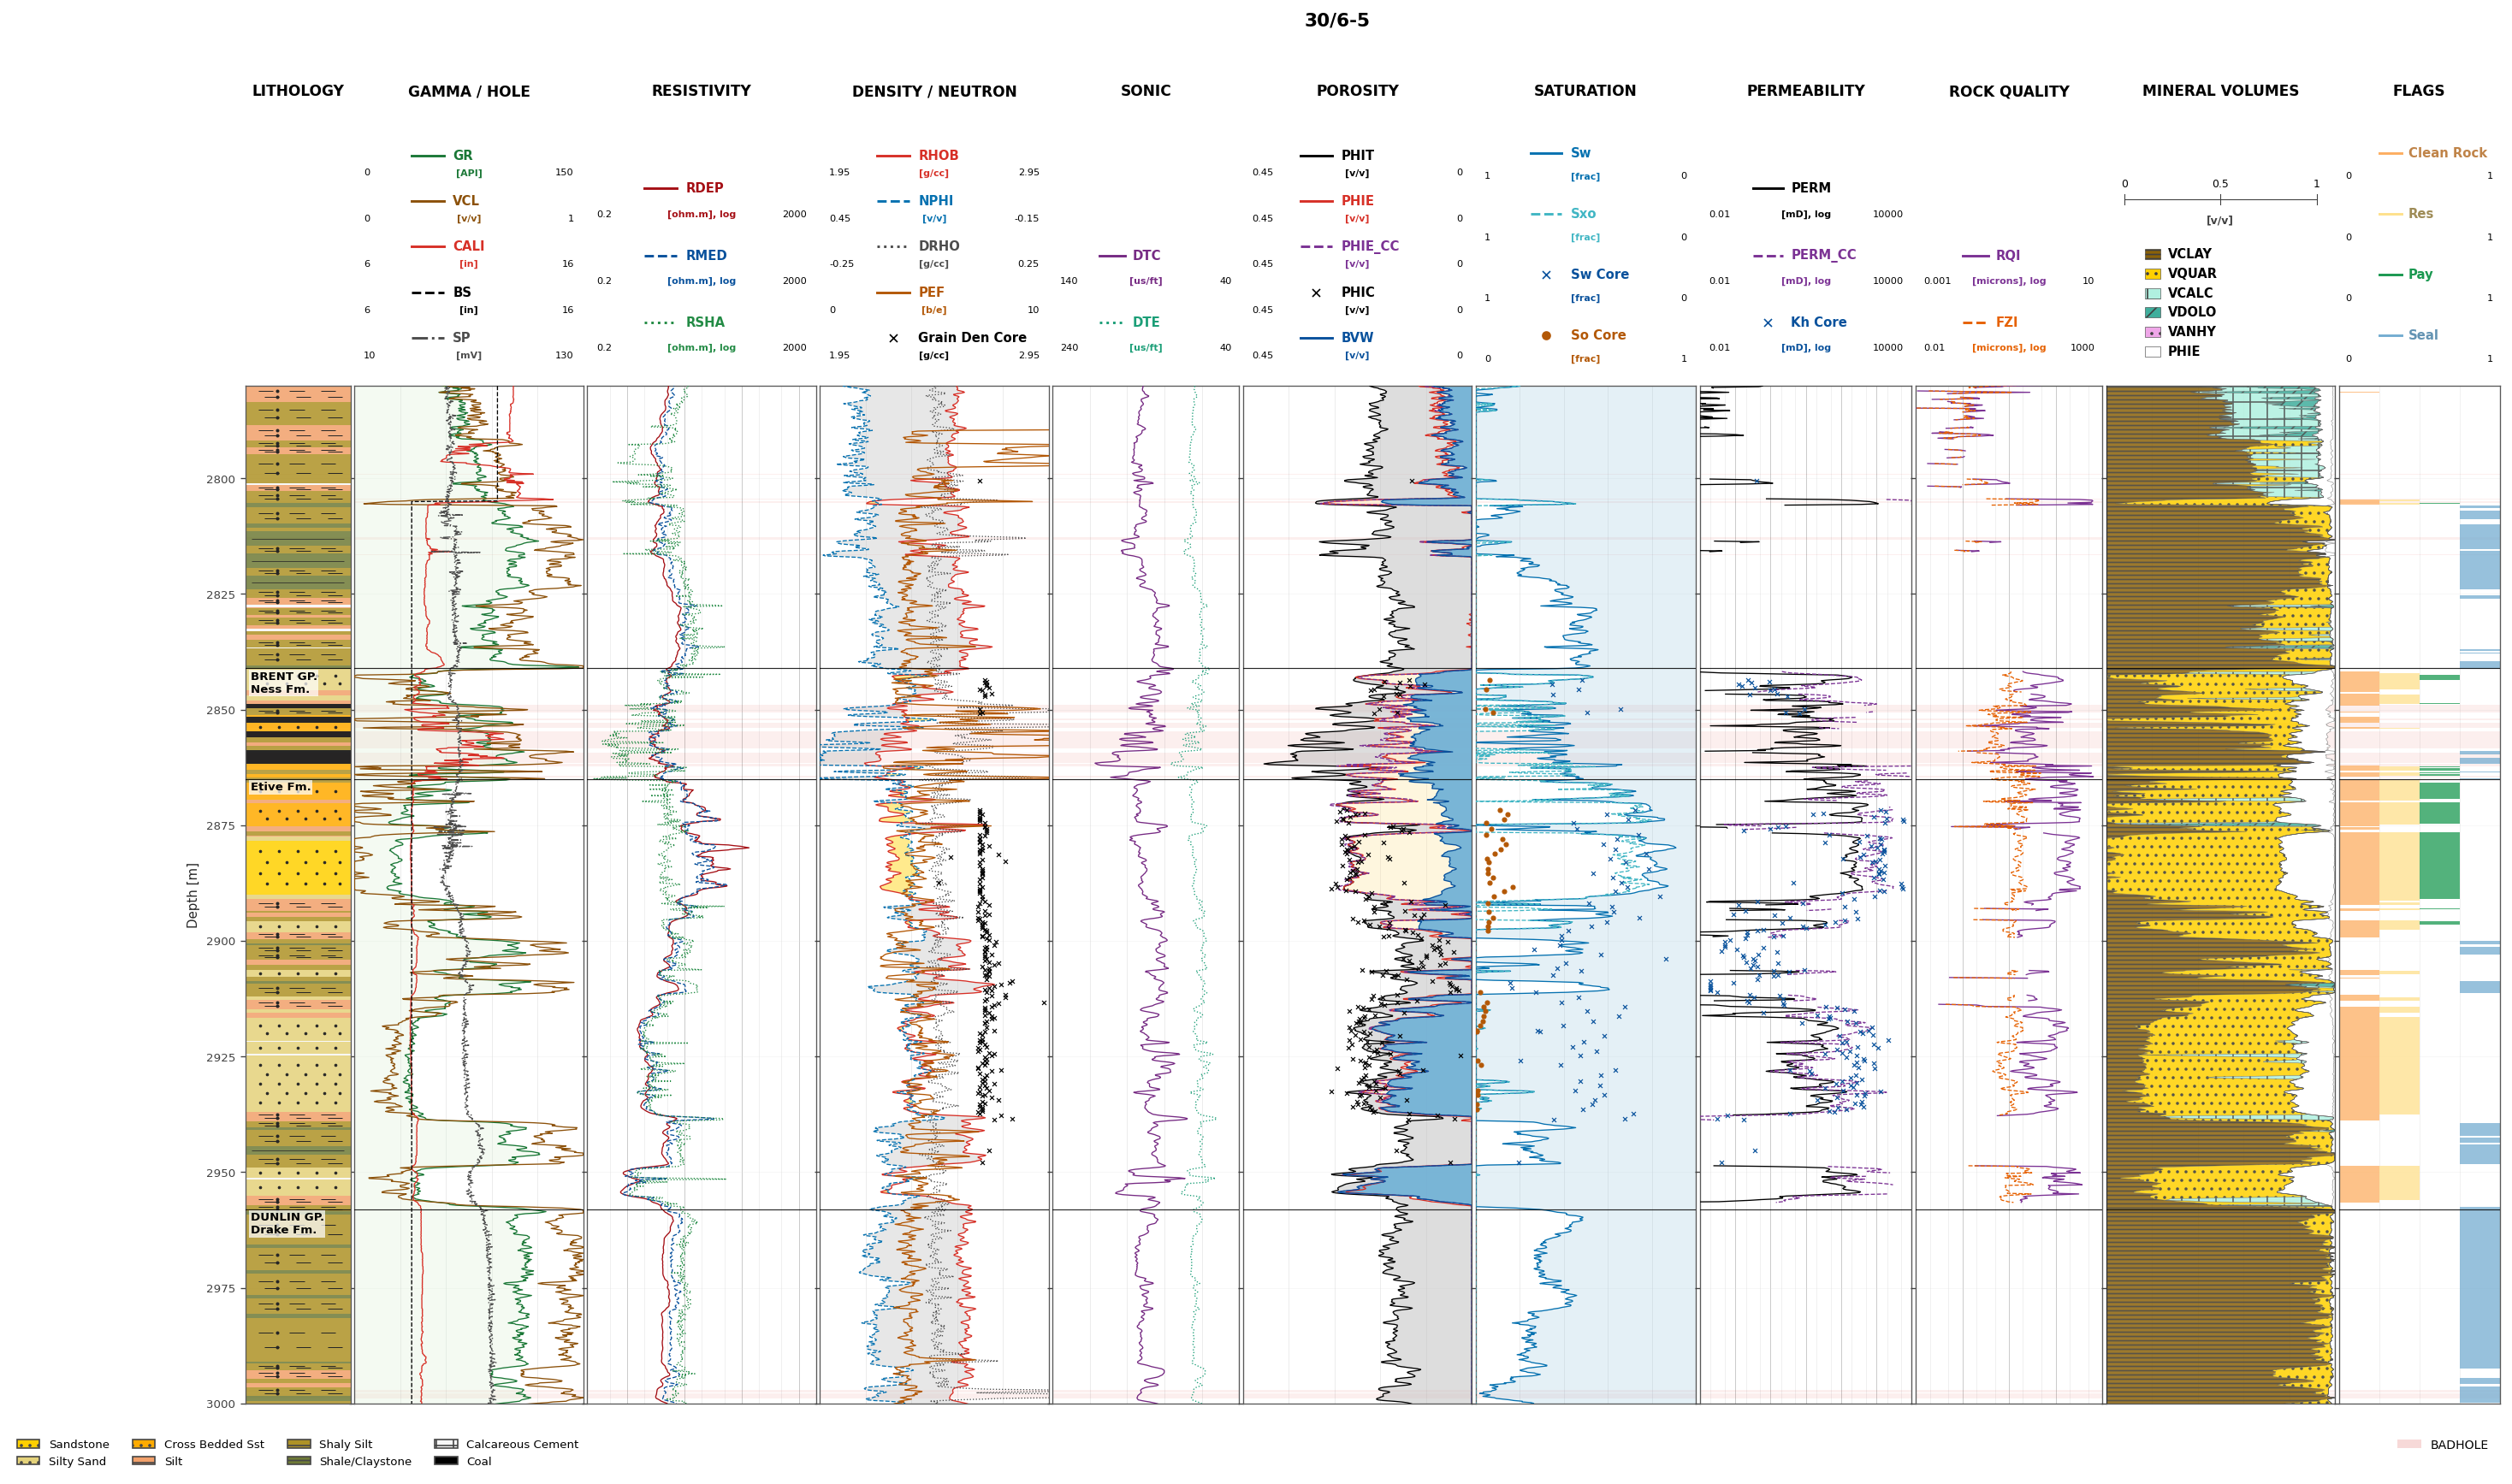

['TEMPERATURE', 'RW / RMF']

In [14]:
viewer = pp.plot(geo_result, top=2780, bottom=3000)
viewer.show()
viewer.diagnostics["optional_tracks"]

The same `auto` template adapts to the carbonate well, which has fewer curves and no
lithology log - note the different track set it produces. Its `PERM` curve sits far to
the right of the dashed `PERM_CC` from the file: the default permeability runs to
thousands of mD (see the HW-3 check above).

In this file RHOB is not on depth with NPHI: RHOB mirrors NPHI best (correlation -0.79,
against +0.11 as recorded) when it is read 55 ft deeper, so the two curves in the
density-neutron track describe different beds. `pp.interpret` warns of it, `find_log_depth_shift` measures the shift and
`shift_curves` moves the curves (RHOB and the sonic, which sits with it):

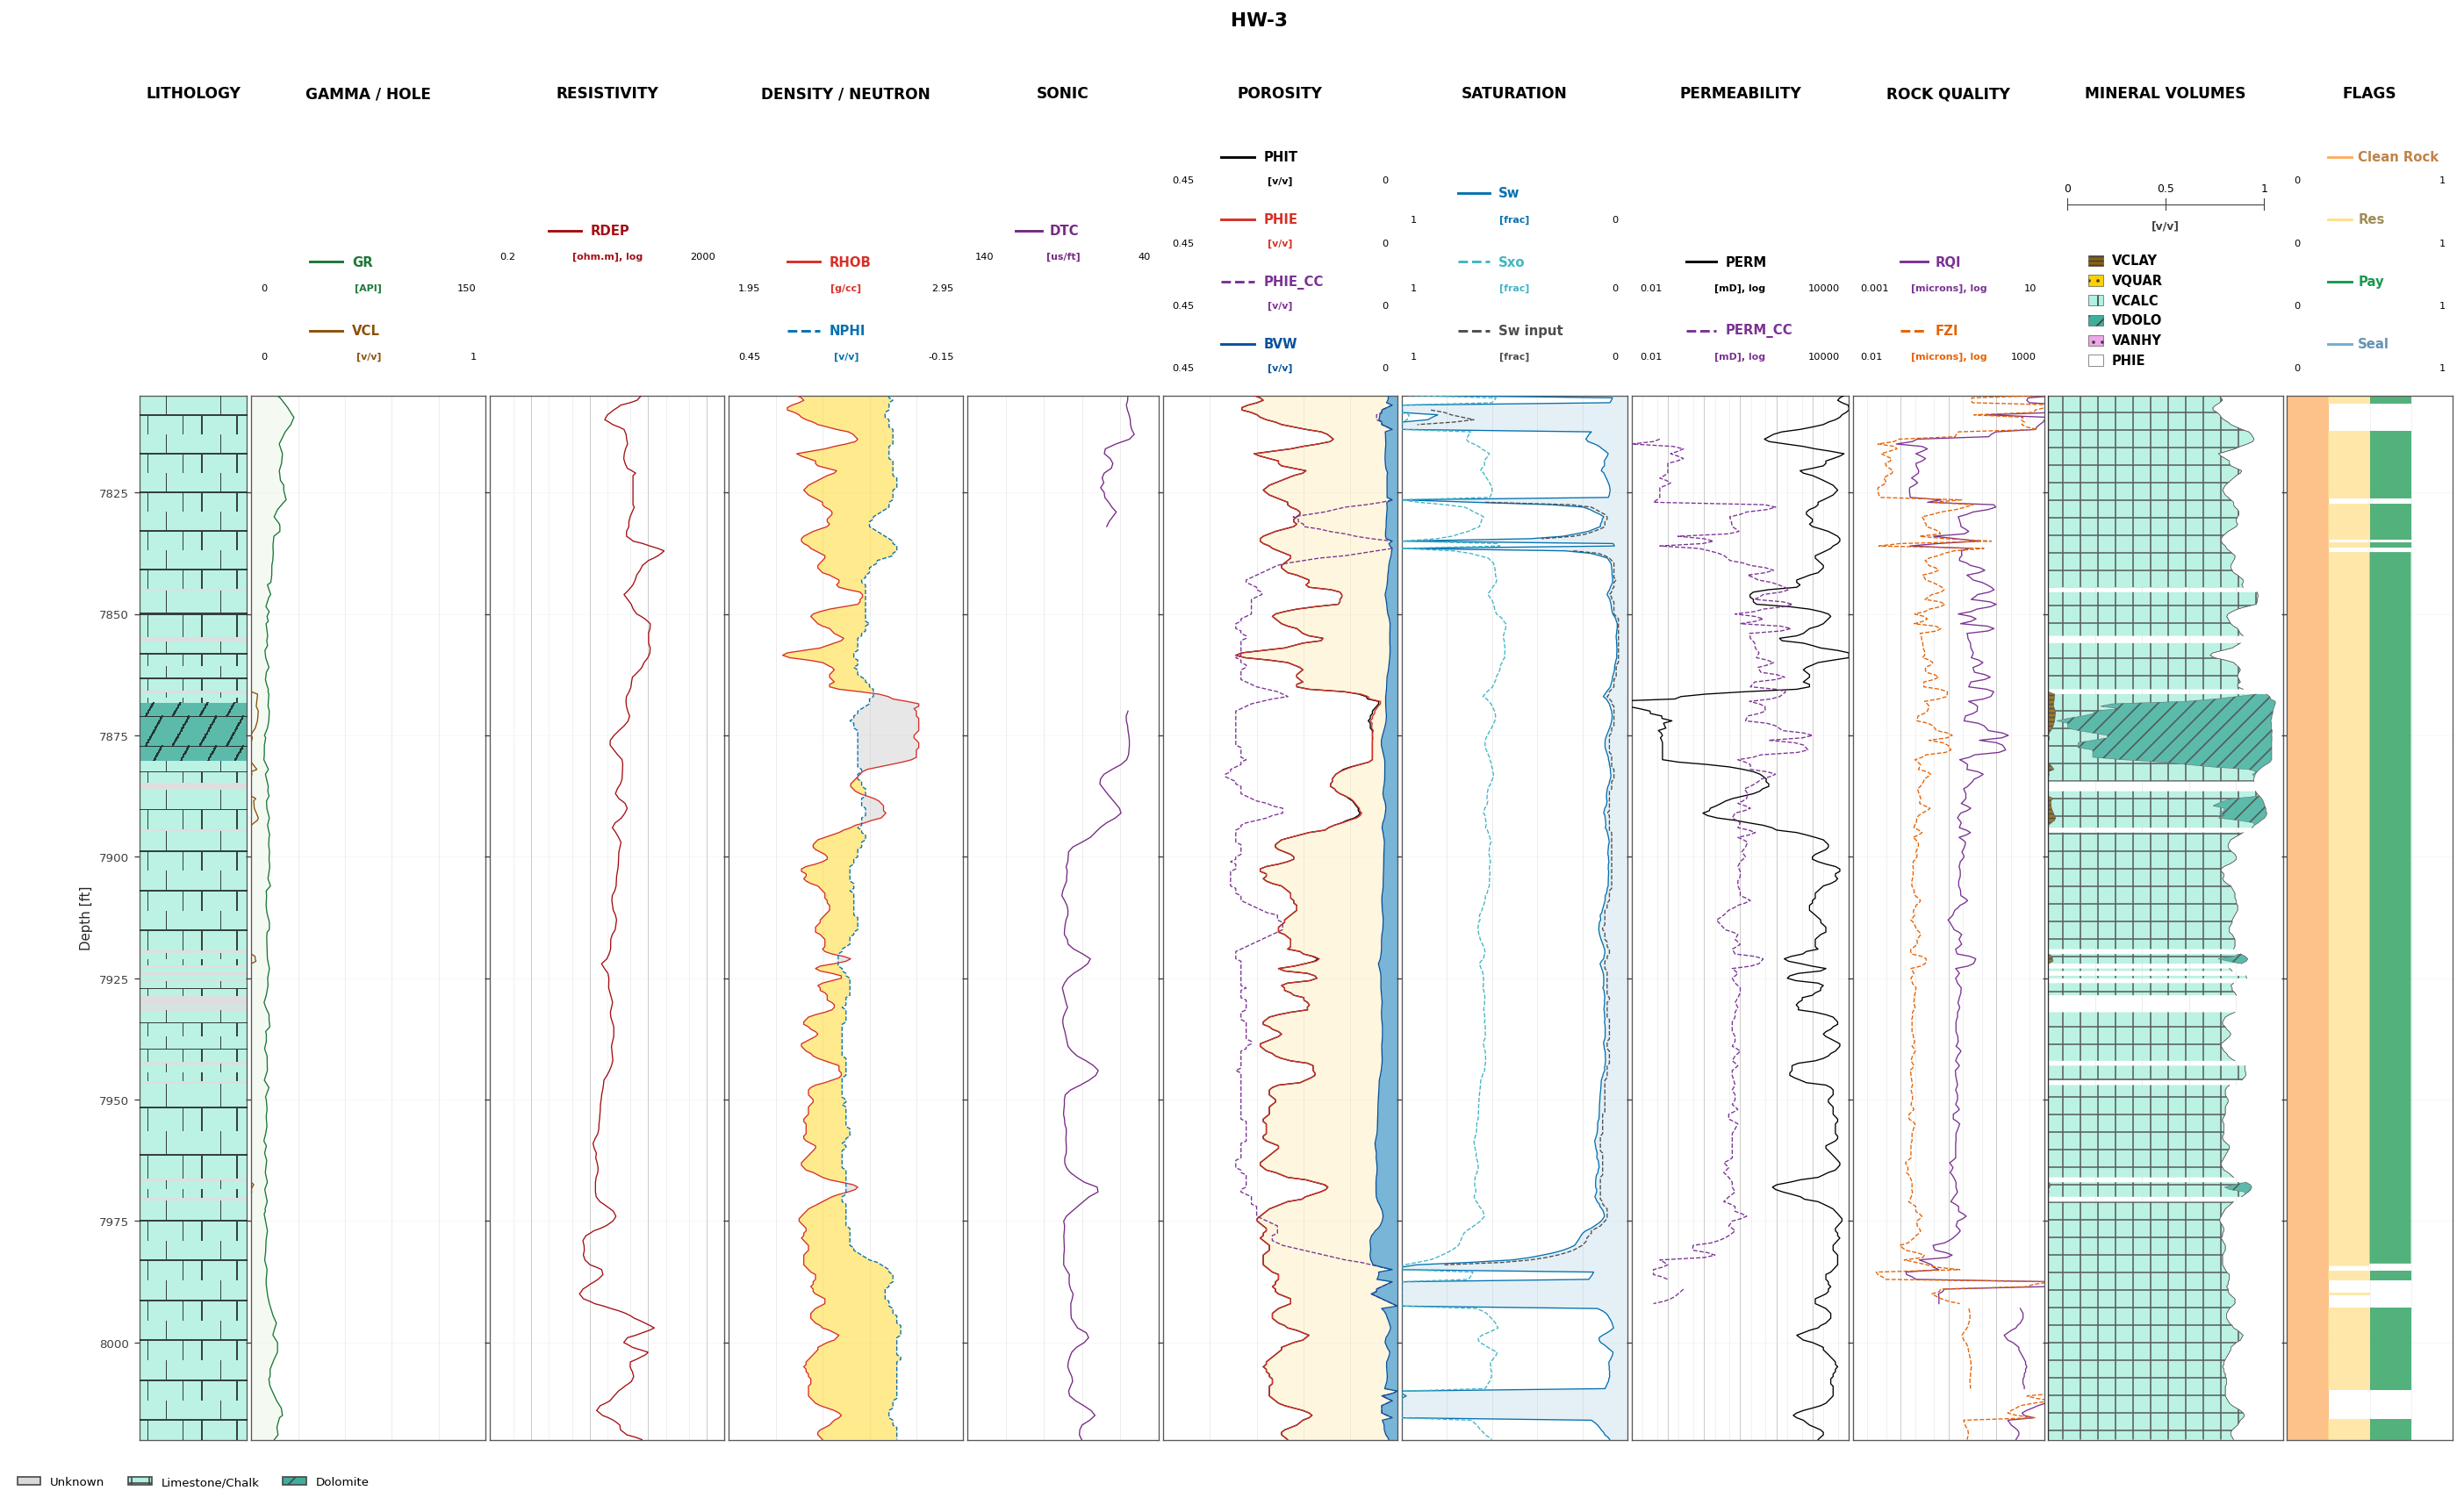

In [15]:
pp.plot(carb_result).show()

In [16]:
from petrophys.preprocessing import find_log_depth_shift, shift_curves

hw3 = pp.read(pp.sample("HW-3"))
found = find_log_depth_shift(hw3, "RHOB", "NPHI")
found

LogDepthShift(RHOB to NPHI: shift -55.00 ft, r = -0.786 (as recorded 0.108), n = 321, searched -65.50 to +65.50 ft)

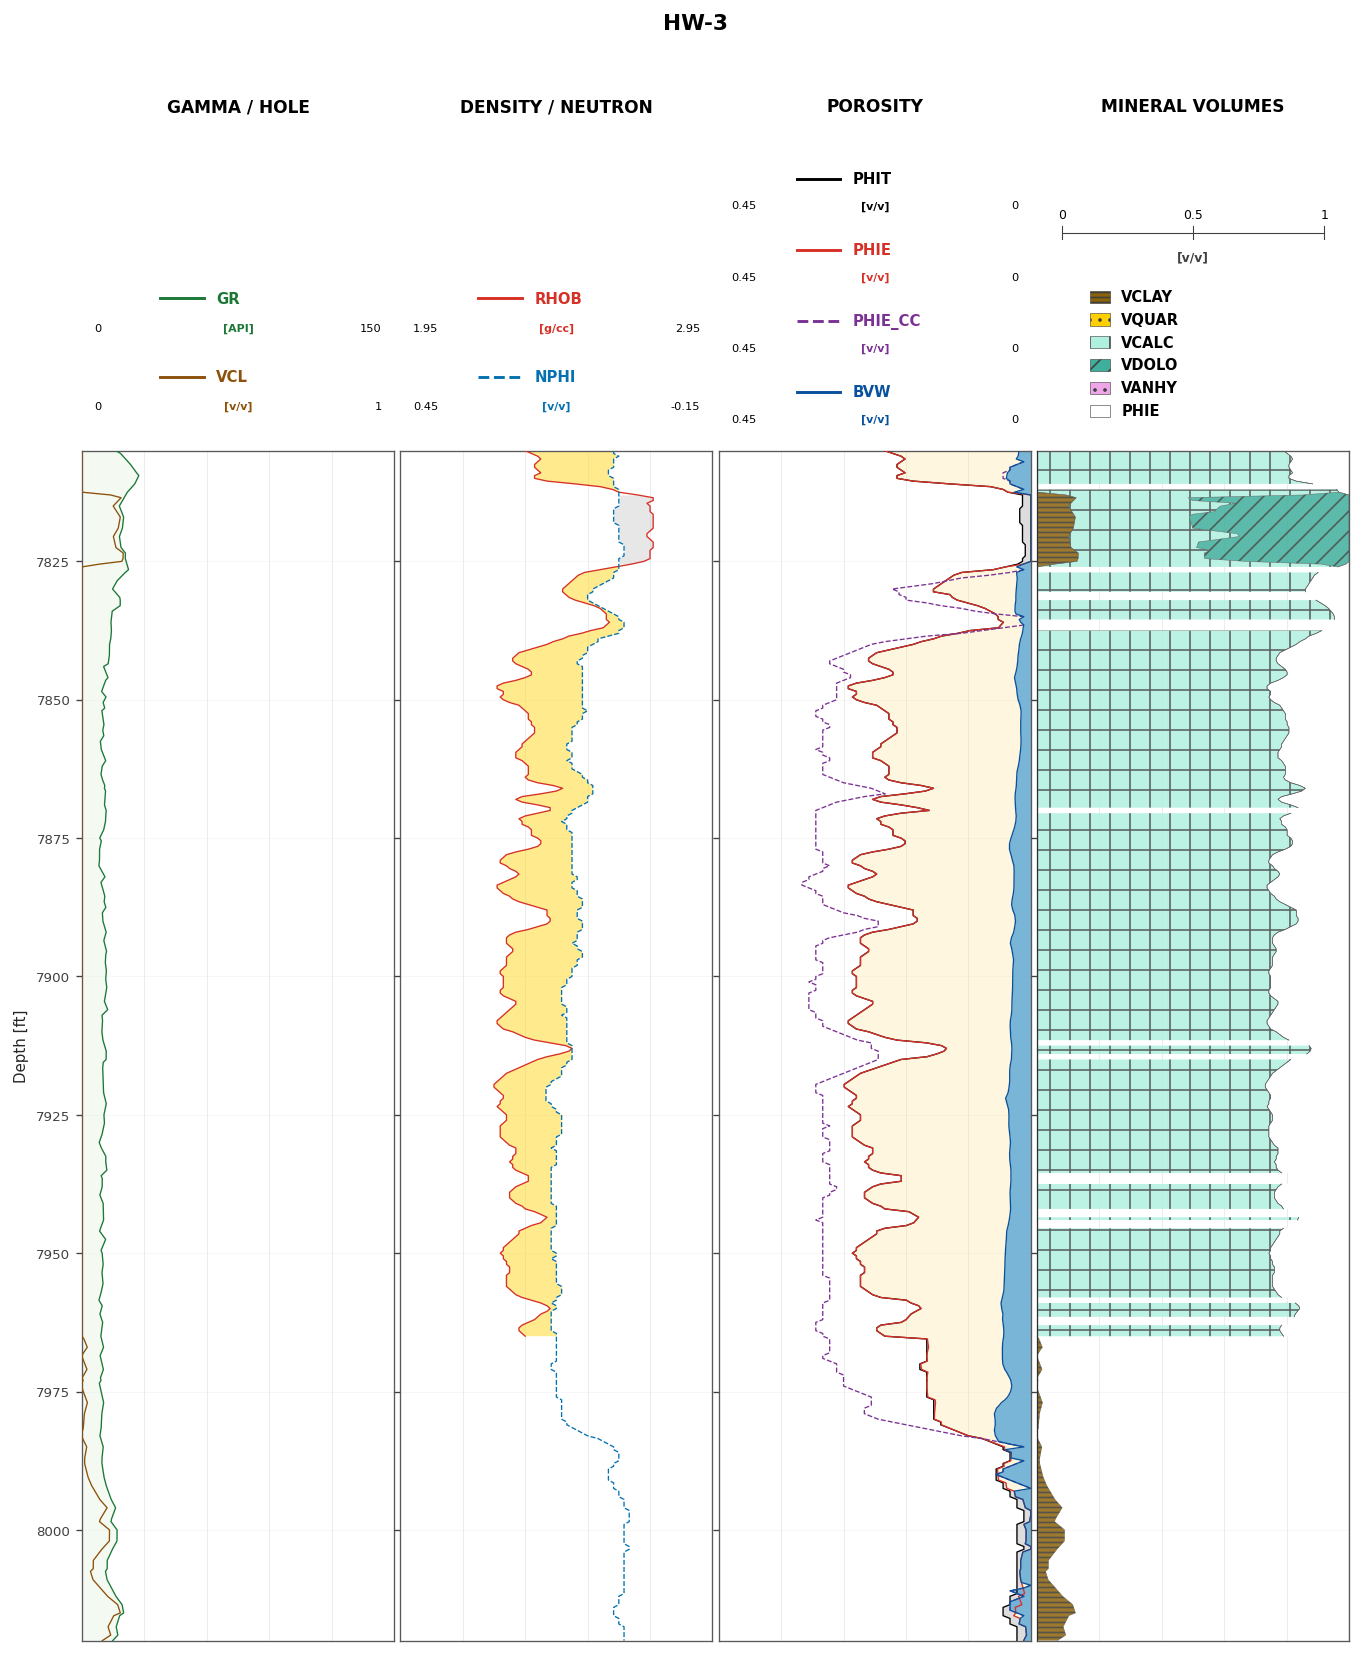

In [17]:
aligned = pp.interpret(shift_curves(hw3, ["RHOB", "DTC"], found.shift), lithology="carbonate")
pp.plot(aligned, tracks=["GAMMA / HOLE", "DENSITY / NEUTRON", "POROSITY", "MINERAL VOLUMES"]).show()

On depth, the tight bed near 7820 ft sits at one depth in every curve. The density-neutron
separation stays: the density still reads more porous than the neutron (median 0.23 against
0.13 on the limestone scale) over 98 % of 7840-7960 ft, where Sw is about 0.1. It is not an
effect of the depth offset.

## 2. Triple combo

`triple_combo` is the classic quick-look, and "triple" means exactly
three measurement families in three tracks:

1. **Correlation** - GR (shaded), SP, and caliper against bit size. SP lives
   here, with GR, per industry convention.
2. **Resistivity** - deep / medium / shallow on a log scale.
3. **Porosity** - neutron and density on compatible scales (NPHI 0.45 to -0.15
   v/v against RHOB 1.95 to 2.95 g/cc), with the DRHO QC curve dotted.

It is the fastest way to eyeball reservoir vs seal and hydrocarbon crossover.
Sonic is deliberately not part of the display - adding it makes a quad combo,
which you can build with a custom template. One call, sensible defaults.

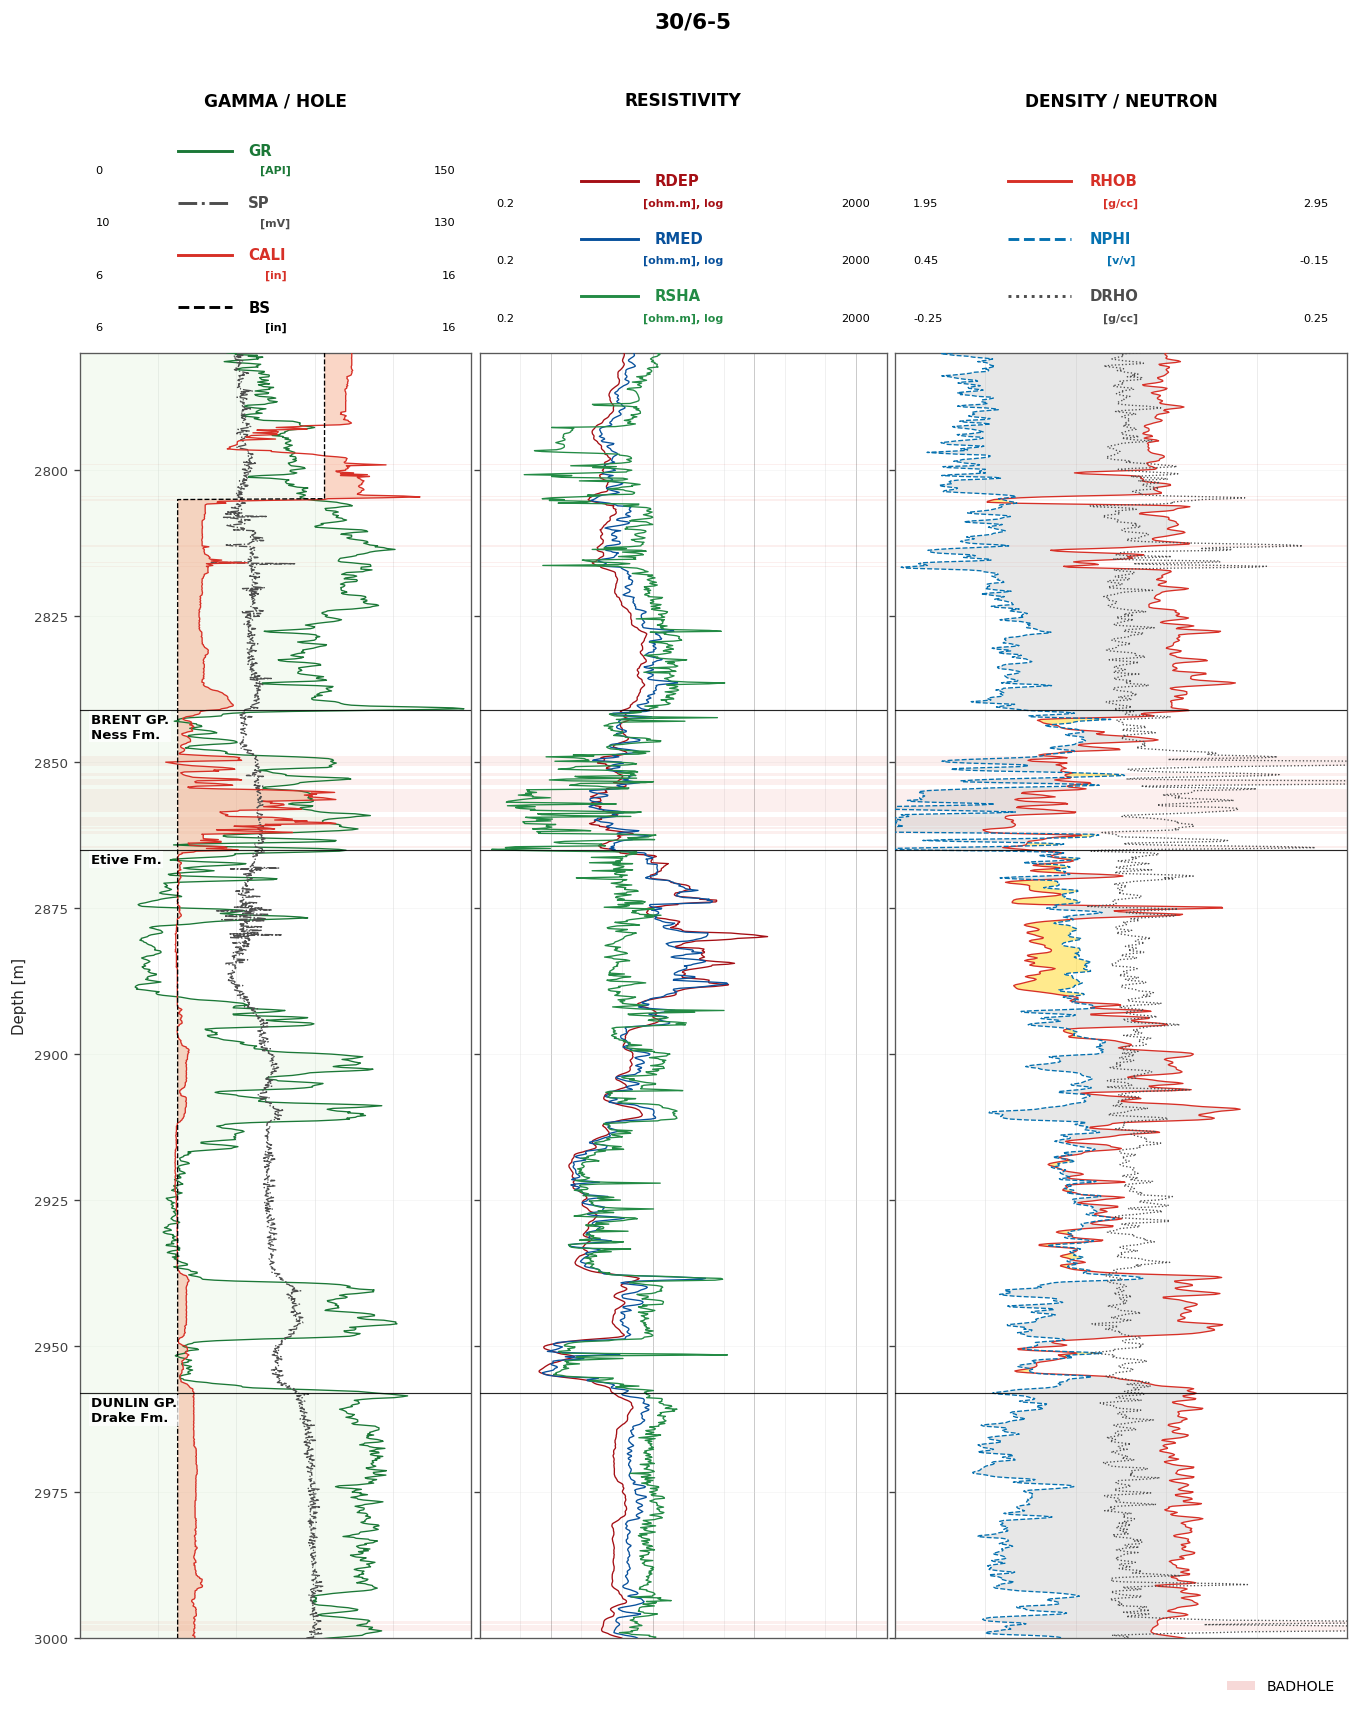

In [18]:
pp.triple_combo(geo_result, depth_range=(2780.0, 3000.0));

## 3. The crossplot family

Crossplots move from depth-vs-value tracks to **value-vs-value** scatter, which is where
lithology, porosity model, and saturation logic become visible.

### 3a. Neutron-density crossplot

`pp.crossplot(result, "NPHI", "RHOB")` plots NPHI against RHOB with lithology lines; points are coloured
by a third curve (default `GR`). Sandstone, limestone, and dolomite trends separate here,
and gas pulls points toward low apparent density / low neutron. We restrict to the
interval where the full lithology suite (including PEF) was recorded on 30/6-5,
2784-3176 m; the N-D crossplot itself uses only NPHI and RHOB, so the PEF offset noted
in section 1 does not affect it.

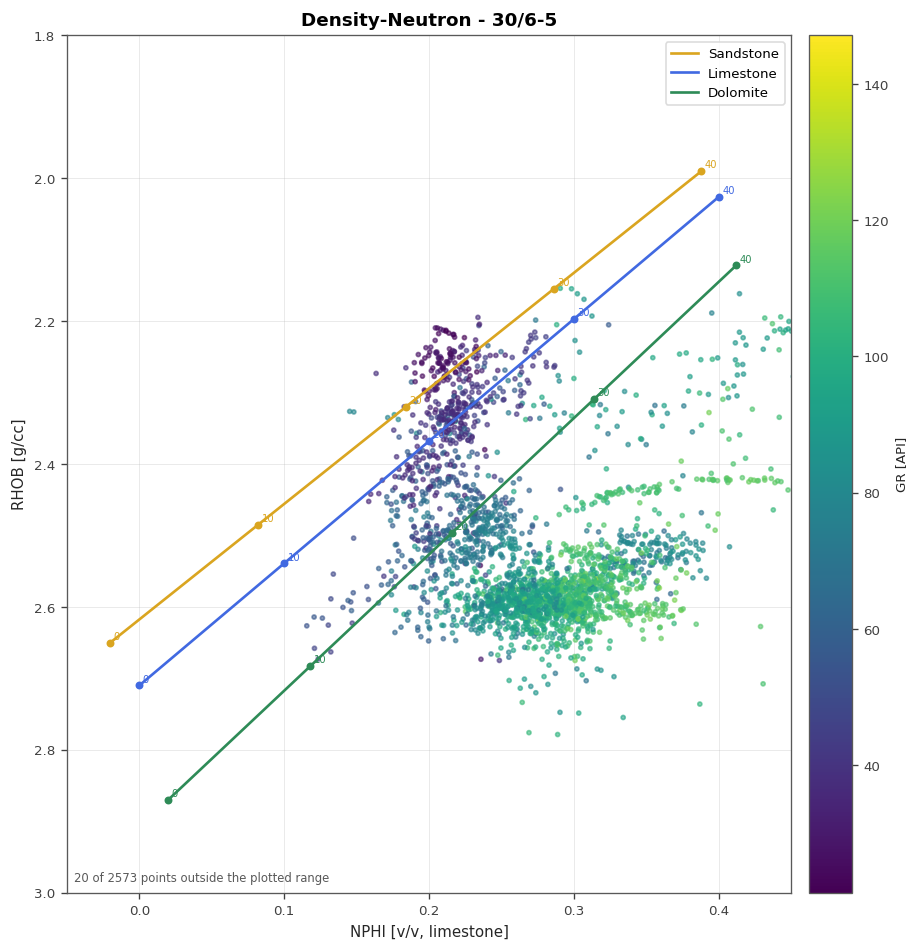

In [19]:
pp.crossplot(geo_result, "NPHI", "RHOB", top=2784, bottom=3176)

### 3b. Pickett plot

`pp.crossplot(result, "PHIE", "RDEP")` draws the Pickett plot, `log(RT)` vs `log(PHIE)`. In a clean, water-bearing zone the
100%-water points scatter about a straight line whose slope is `-m` (its magnitude is the
cementation exponent) and whose intercept fixes `Rw`. Hydrocarbon points sit **above**
the water line. We run it on the Statfjord water sand, 3223-3556 m (a hydrocarbon
interval would give too few water points).

The parameters are not free knobs: we use the operator's own evaluation constants
(a=0.80, m=n=2, from the Statoil completion report validated in lesson 09). For Rw,
the plot takes the median of the interpretation's `RW` curve over the plotted
points: the operator's 0.070 ohm.m at 230 degF, moved by the workflow to the hotter
Statfjord, about 0.066 ohm.m. It plots clean rock only, `VCL` up to 0.15 (`vcl_max`), and
notes how many shaly samples it leaves out. Read the plot for the slope and the position of
the clean points: most lie between the Sw=100% and 80% lines, some just below the water
line - close to wet, as a water sand should be. Had they plotted well inside the Sw lines (an apparent Sw of 60-80% across a wet
sand), Rw would be too low - the classic mis-parameterised Pickett from lesson 07.

[repository]\src\petrophys\visualization\style.py:102: DataQualityWarning: Pickett input: 20 of 22176 value(s) require porosity in (0,1] and finite positive resistivity (zero-based flat indices [20974, 20975, 20976, 20979, 20980]). Invalid points are omitted from this plot.
  return _label_short_log_axes(function(*args, **kwargs))


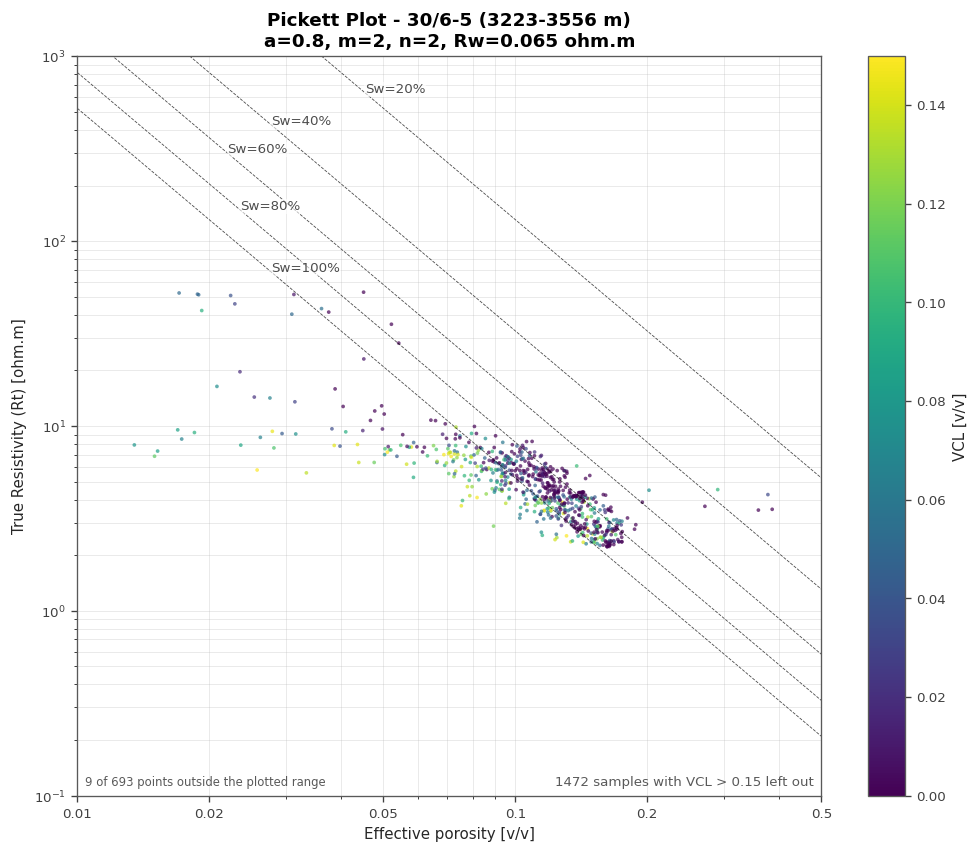

In [20]:
pp.crossplot(geo_result, "PHIE", "RDEP", top=3223, bottom=3556, a=0.80, m=2.0, n=2.0)

### 3c. Hingle plot

`chart="hingle"` draws the Pickett plot's linear-grid cousin, the Hingle plot: it linearises the Archie
relation so the water line and `Rw` can be read on ordinary axes. Same water interval,
parameters, Rw and clean points, different projection - useful when you want to fit the
water line by eye. On this projection wetter rock plots higher (more conductive at a given
porosity). The clean points hug the Sw=100% line, many of them slightly below it, as the
Pickett plot's water points sit slightly above its water line; the tightest points, below
0.05 porosity, plot above it, where a small error in porosity moves a point far.

[repository]\src\petrophys\visualization\style.py:104: DataQualityWarning: Hingle input: 20 of 22176 value(s) require porosity in (0,1] and positive resistivity (zero-based flat indices [20974, 20975, 20976, 20979, 20980]). Invalid points are omitted from this plot.
  return _label_short_log_axes(function(*args, **kwargs))


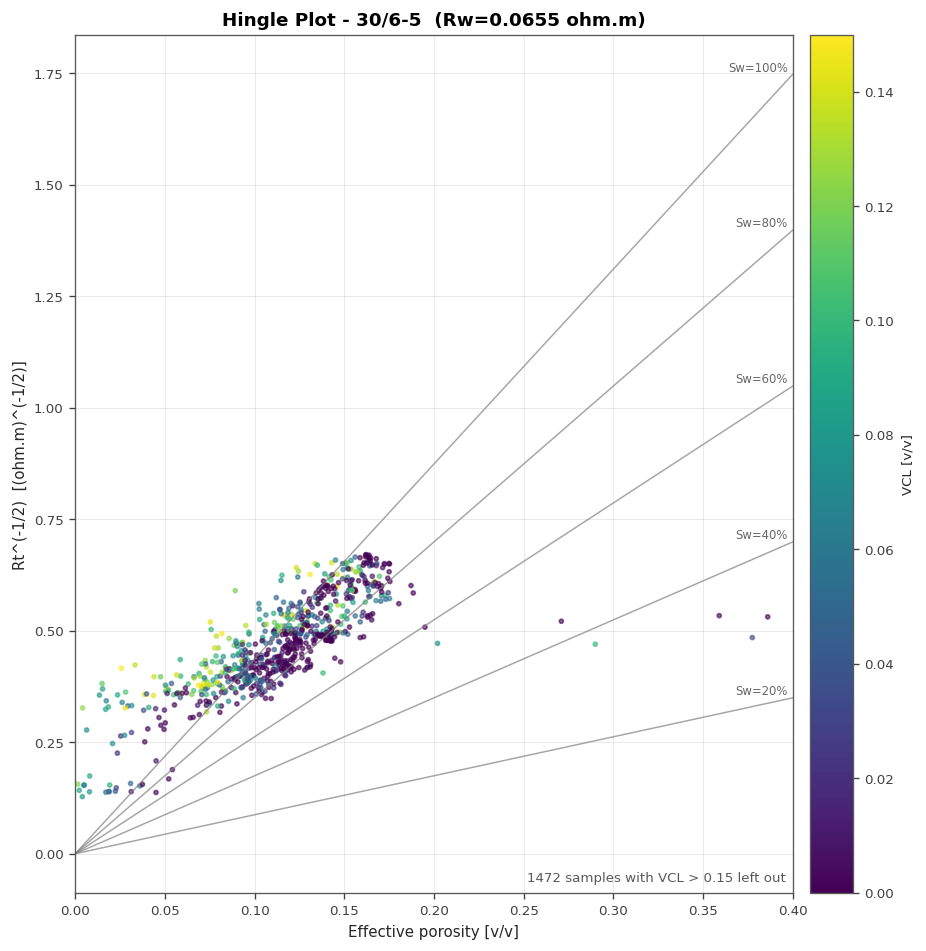

In [21]:
pp.crossplot(geo_result, "PHIE", "RDEP", chart="hingle", top=3223, bottom=3556, a=0.80, m=2.0, n=2.0)

### 3d. M-N and MID lithology crossplots

`pp.crossplot(result, "N", "M")` uses density, limestone-referenced neutron and sonic to compare
samples with linear freshwater/mineral references. The MID plot, `pp.crossplot(result, "DTMAA", "RHOMAA")`, removes the
fluid contribution from density and sonic using `PHIT`. Select another independently
determined total-porosity curve with `porosity_curve="MY_PHIT"`. If PHIT is absent,
it estimates porosity from clean quartz/calcite/water and calcite/dolomite/water
triangles; samples outside that model warn and are omitted. These overlays are not
vendor-specific neutron response charts. Coloured by `GR`.

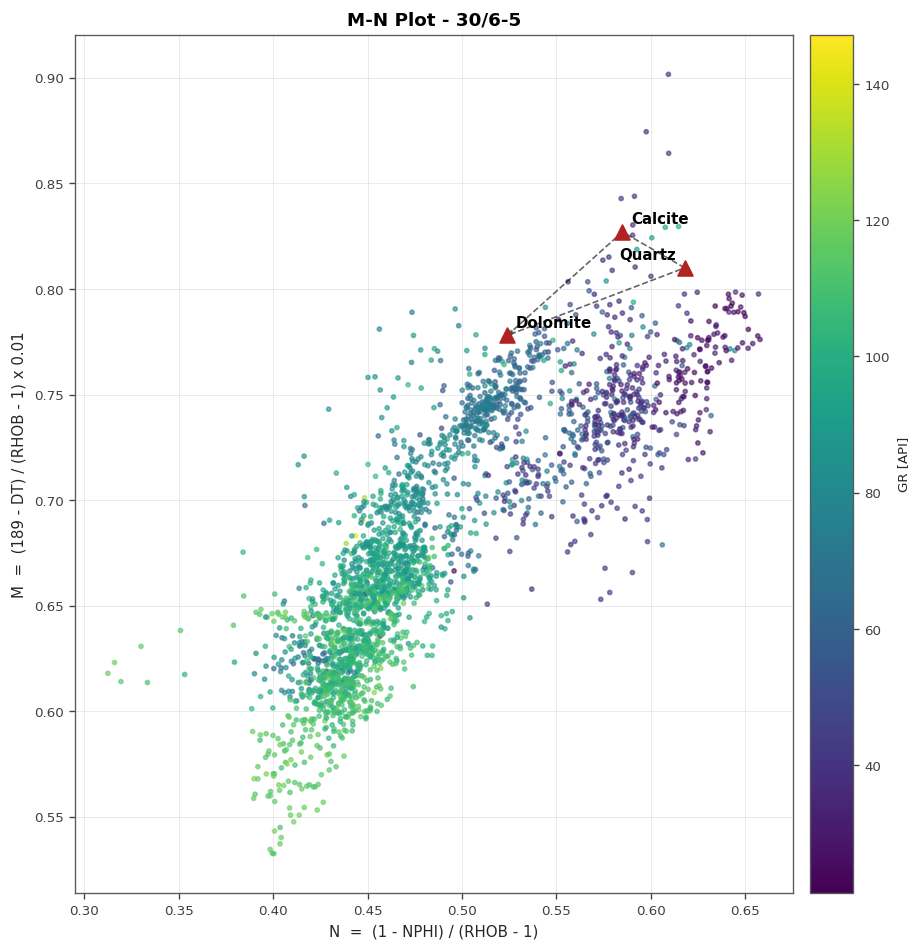

In [22]:
pp.crossplot(geo_result, "N", "M", top=2784, bottom=3176)

The MID corner note counts finite points outside the chart. Shale, gas, complex
mineral mixtures and errors in total porosity can all shift apparent matrix
coordinates. Compare the low-GR population with the mineral markers, and check the
porosity model before interpreting displaced points as a mineral change.

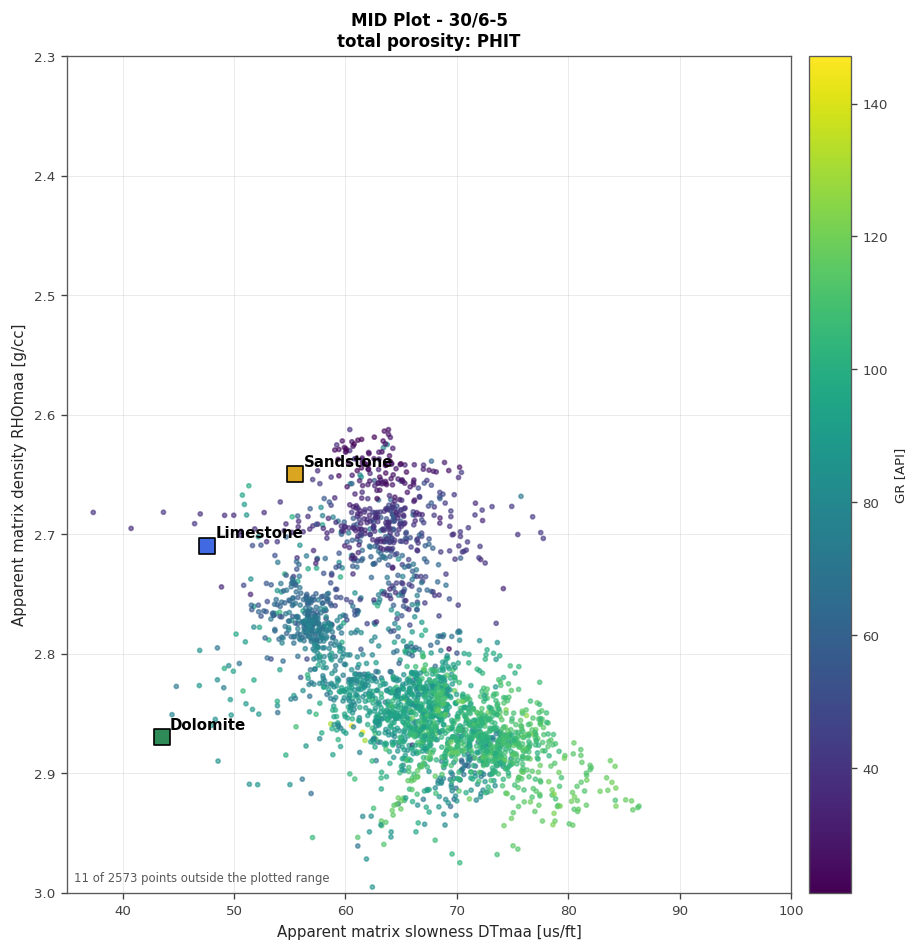

In [23]:
pp.crossplot(geo_result, "DTMAA", "RHOMAA", top=2784, bottom=3176)

### 3e. Buckles plot

`pp.crossplot(result, "PHIE", "SW")` shows `PHIE` vs `SW`; points on a common `PHIE * SW = const`
hyperbola share **constant bulk-volume water**. This can support an irreducible-water
interpretation, but does not establish it or predict water-free production by itself. Coloured by permeability. This is a carbonate reservoir
question, so we run it on HW-3 (its LAS covers the Kharaib-2 reservoir interval).
The colour scale carries little information about the rock here: the default
HW-3 `PERM` is uncalibrated (median in the thousands of mD; see the HW-3 check),
so the colour mostly follows porosity. Read the plot for its PHIE-SW pattern.

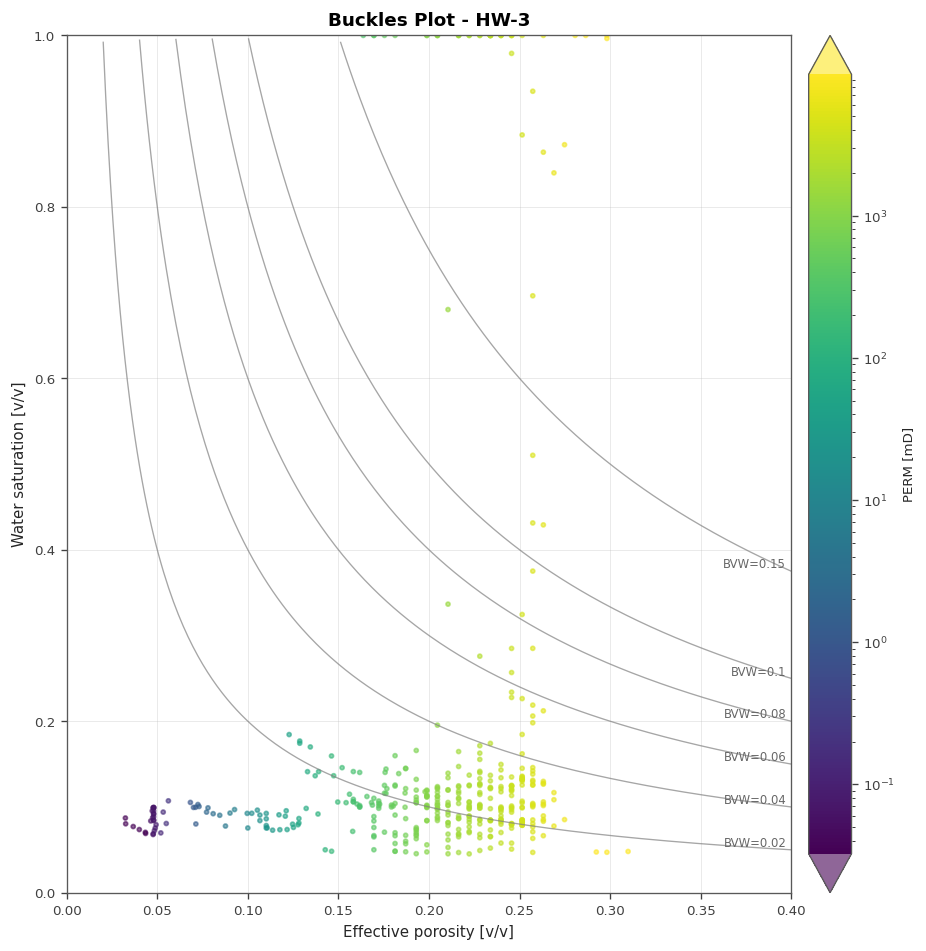

In [24]:
pp.crossplot(carb_result, "PHIE", "SW", color="PERM")

## 4. Specialist panels

### 4a. Flow-unit (RQI vs phi_z) plot

`pp.crossplot(core, "PHI_Z", "RQI")` renders a Reservoir Quality Index / flow-zone-indicator analysis
from porosity and permeability. The analysis only separates units when permeability
genuinely varies at fixed porosity, so we feed it **real core plugs**: 30/6-5 carries
`PHIC` (core porosity) and `KH_CORE` (core horizontal permeability) at the plug depths,
and `core_data` collects them as core data.
A log-derived `PERM` curve would be a poor input here - the dynamic workflow computes it
*from* porosity, so its FZI collapses onto a single trend by construction. On the
log-log RQI-vs-phi_z axes each unit clusters around its own constant-FZI line, so the
units stack as parallel diagonal bands.

[temporary directory]\ipykernel_20428\1717562655.py:1: UserWarning: SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  pp.crossplot(core_data(raw_geo), "PHI_Z", "RQI")
[temporary directory]\ipykernel_20428\1717562655.py:1: UserWarning: SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  pp.crossplot(core_data(raw_geo), "PHI_Z", "RQI")


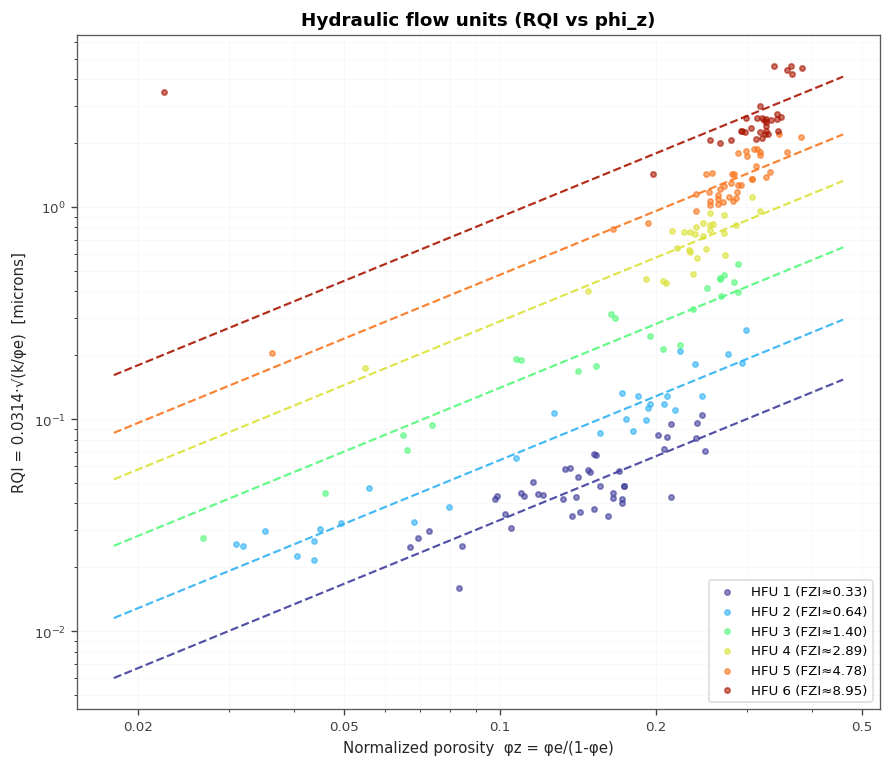

In [25]:
pp.crossplot(core_data(raw_geo), "PHI_Z", "RQI")

### 4b. NMR panel - real CMR (Daydream 1)

`nmr_panel` builds the standard CMR display: GR with cable tension (CDF, TENS), borehole calipers,
CMR porosity split into bound and free fluid, NMR permeability, and Swirr with
the T2 cutoff (a single cutoff is stated in the track title). It needs NMR summary curves such as `TCMR`, `CMFF`, `KTIM`;
`has_nmr_curves(well)` tells you whether a well qualifies.

Neither teaching well carries NMR, but the package bundles the **real
Daydream 1 CMR log** (lesson 14 works it end to end), and its curves are
exactly what the panel wants. The window below, 3900-4100 m, holds some of
the high-TCMR streaks that lesson 14 flags for QC.

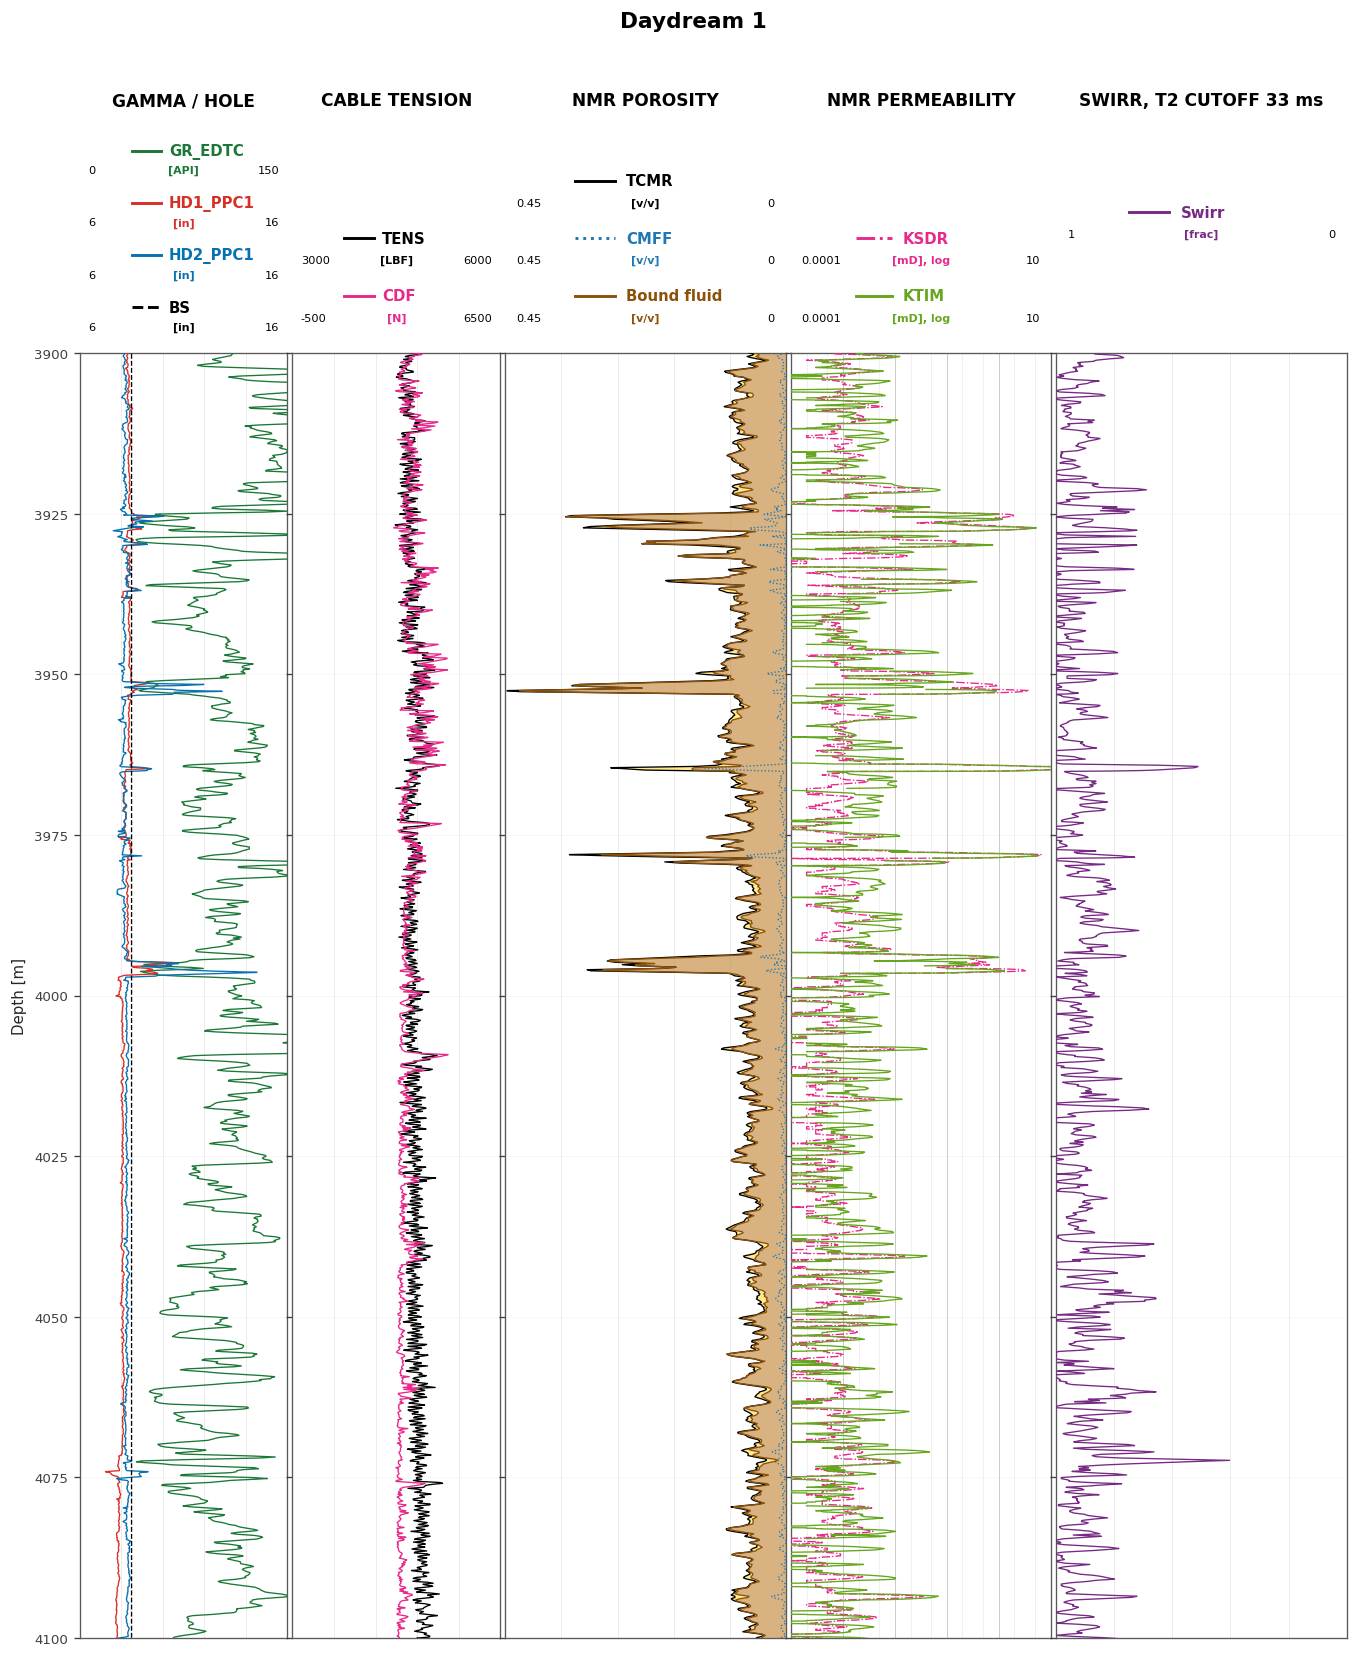

In [26]:
pp.nmr_panel(pp.read(pp.sample("daydream1_cmr")), depth_range=(3900.0, 4100.0));

### 4c. FMI panel - rendered in lesson 16

`fmi_panel` takes a `BoreholeImageData` (a pad/button resistivity image
plus a navigation curve), orients it to azimuth, equalizes, and renders the
standard image display. The Daydream image DLIS (about 110 MB) is not in the
Python wheel, so the panel is not rendered here. Lesson 16 renders it: it needs
the `[dlis]` extra and downloads the image file on first use (or reads the file
the `PETROPHYS_FMI_DLIS` environment variable points to).

## 5. Zone flags

`zone_flags_plot` renders discrete flag curves (net rock / reservoir / pay) as coloured
bars against depth - an at-a-glance summary of where the pay is. Over the Heather shale
and the Brent Group the net-pay flag concentrates in the Brent sands.

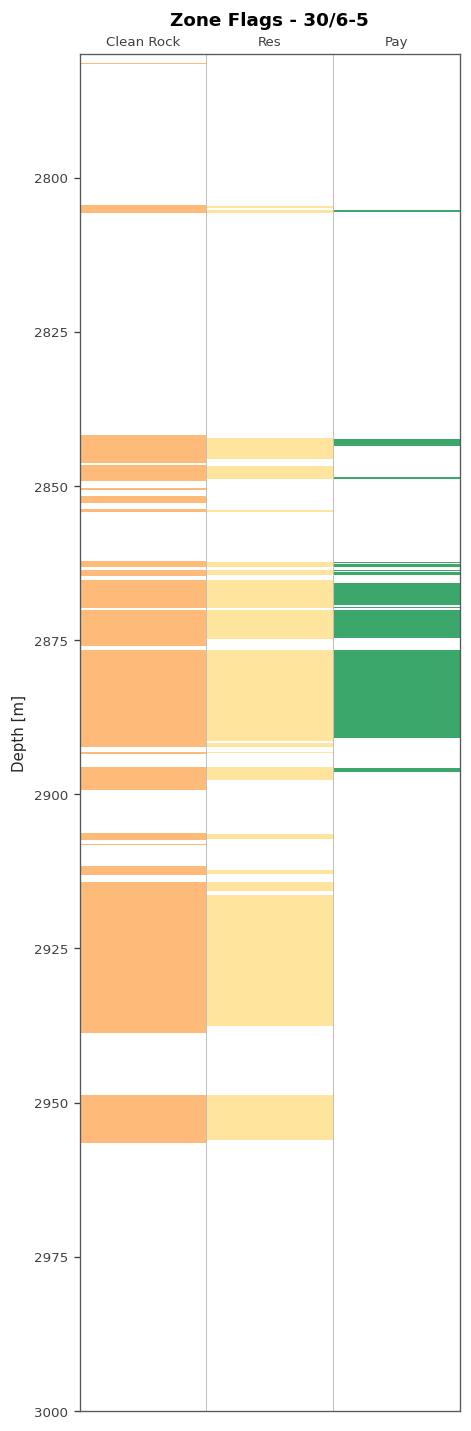

In [27]:
pp.zone_flags_plot(geo_result, flag_curves=["NET_ROCK", "NET_RES", "NET_PAY"], depth_range=(2780.0, 3000.0));

The formation tops attached with `pp.read(..., formations=...)` mark the same
intervals on every `pp.plot` figure (see the plot with external geology above).
`add_zone_shading(ax, zones)` adds translucent depth bands to any matplotlib axis you
draw yourself.

## 6. Several wells in one figure

Field work compares wells. `pp.plot` takes several wells (a list, the wells `pp.read`
returns for a folder or a list of files, or the results of `pp.interpret` on them):
with `curves=` it draws one figure with a track per curve and every well's curve in
it. The analytics helpers cover the charts that are not depth tracks:

- `histograms` - overlaid distributions;
- `bar_chart` - single or grouped ranking bars;
- `multiwell_overlay` - one curve versus depth across several wells, optionally
  scaled 0-1 so their shapes compare;
- `tornado_plot` and `line_chart` - a sensitivity tornado and
  generic x-versus-many-series lines, from plain arrays.

We demonstrate `pp.plot` on several wells and the first two helpers on real North Sea wells.

### 6a. Compare wells along depth

Four North Sea wells read in one call. Over 2000-2600 m, a depth all four logged, each
track holds one curve from every well. At one depth different wells cut different
stratigraphy, so this is a cross-well QC view (scales, units, tool character), not a
correlation; for GR normalization compare distributions (6b) rather than traces. The
`DataQualityWarning` lines under the cell name values the plot set aside while
standardizing the wells' curves: resistivity samples at a 2000 ohm.m ceiling, and
a sonic curve of 15/9-14 (`DTE`) with no plausible values.

[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:855: UserWarning: SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)
[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:855: UserWarning: SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)
[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:1173: DataQualityWarning: RMED: 58 of 18648 samples sit at the curve's maximum 2000 ohm.m, a tool or computation ceiling rather than a reading, and were removed.
  return standardizer.standardize(well)
[repository]\src\petrophys\visualization\log_viewer.py:2035: DataQualityWarning: DTE: 20181 of 20181 samples are outside the plausible DTE range 20 to 600 us/ft and were removed.
  standardize_curves(
[reposit

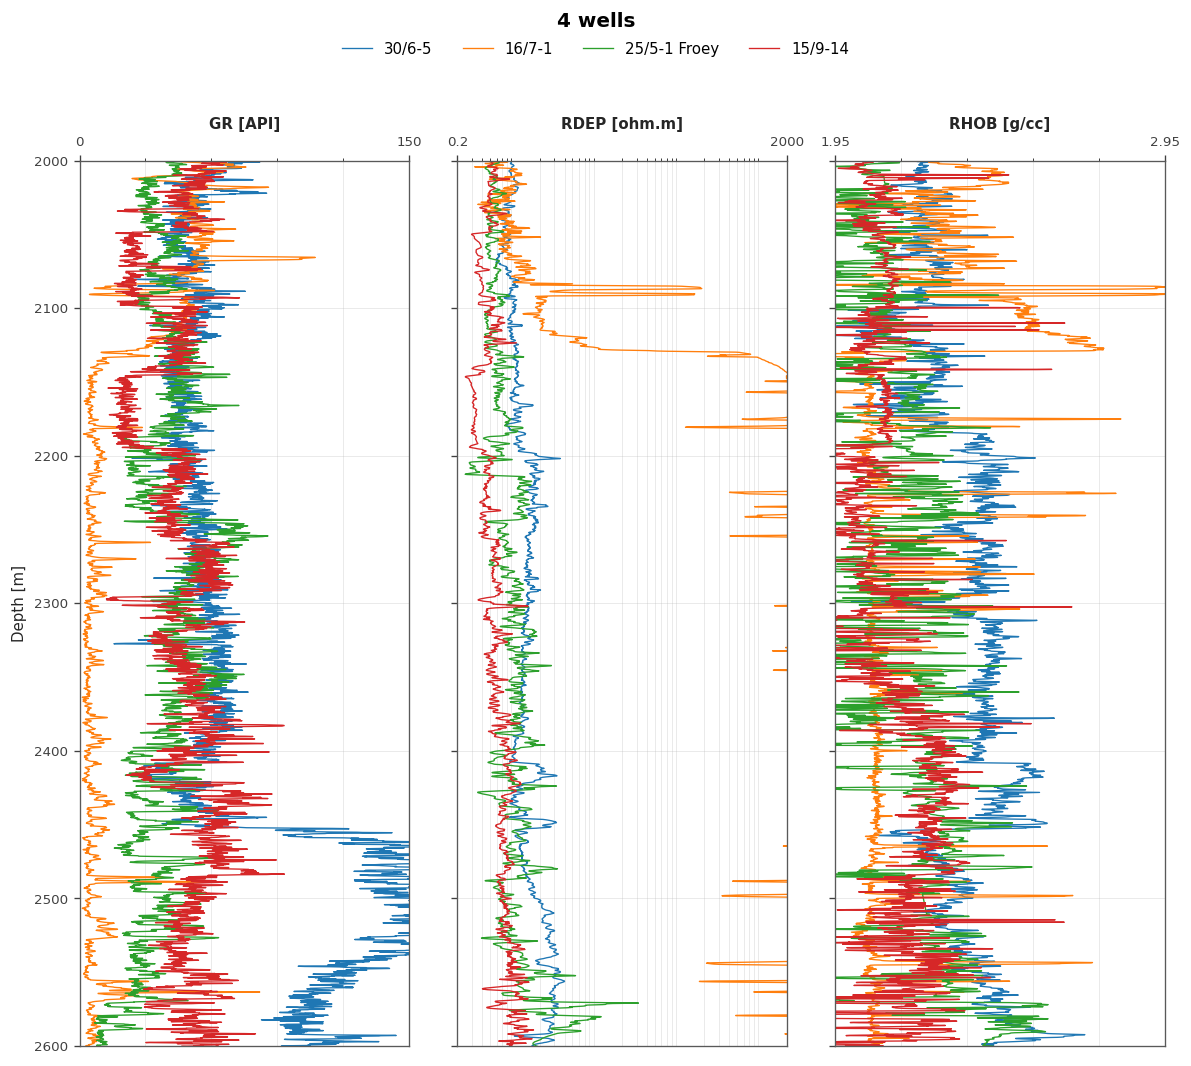

In [28]:
field = pp.read([pp.sample(name) for name in ["30_6-5", "16_7-1", "25_5-1", "15_9-14"]])
pp.plot(field, curves=["GR", "RDEP", "RHOB"], top=2000, bottom=2600, figsize=(10, 9)).show()

### 6b. Histogram comparison

`histograms(wells, "GR")` overlays one curve's distributions from
several wells on a common bin grid (a `{label: array}` mapping works too). A classic use is comparing a curve's spread across wells (or
before/after normalization); here we compare each well's GR distribution. `histtype="step"` keeps several wells
readable and `value_range` keeps a few spikes from stretching the bins.

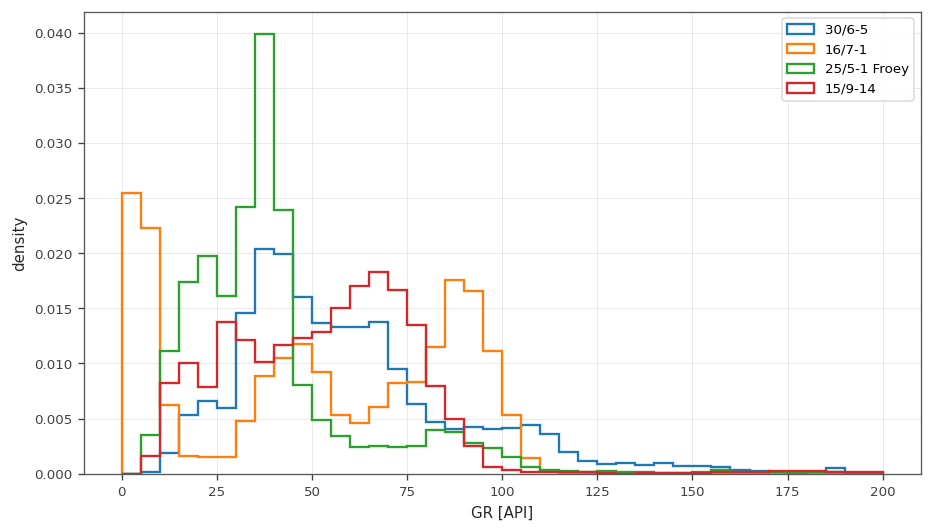

In [29]:
pp.histograms(field, "GR", bins=40, density=True, value_range=(0, 200), histtype="step");

### 6c. Grouped bar comparison

`bar_chart(categories, values, ...)` draws single or grouped bars.
`values` may be a 1-D sequence or a `{series: values}` mapping for grouped bars;
`sort_by` ranks the categories by a chosen series. Here it charts the formation summary
of the 30/6-5 interpretation - net rock, net reservoir and net pay per formation from
`formation_summary` - for the formations from the Heather Fm. down (tops at or below
2593 m), kept in stratigraphic order (no `sort_by`). The 1.4 m of net pay in the Heather Formation is
nine single samples, not a reservoir: seven in silty beds at 2710-2735 m that pass the
cutoffs only just (VCL 0.34-0.40 against 0.40, Sw 0.56-0.58 against 0.60), and two at
2805 m where the combined clay volume reads 0.04-0.07 under a gamma ray of 95 API.

In [30]:
fsum = geo_result.formation_summary(rank="formation").query("Top >= 2593")
fsum[["Formation", "Top", "Bottom", "Gross (m)", "Net Rock (m)", "Net Reservoir (m)", "Net Pay (m)"]].round(1)

,Formation,Top,Bottom,Gross (m),Net Rock (m),Net Reservoir (m),Net Pay (m)
5,Heather Fm.,2593.0,2841.0,248.0,13.0,5.2,1.4
6,Ness Fm.,2841.0,2865.0,24.1,11.1,7.6,2.6
7,Etive Fm.,2865.0,2958.0,93.0,65.4,58.4,23.5
8,Drake Fm.,2958.0,3071.0,113.1,0.0,0.0,0.0
9,Cook Fm.,3071.0,3123.0,52.0,9.6,0.8,0.0
10,Amundsen Fm.,3123.0,3223.0,100.0,0.0,0.0,0.0
11,Statfjord Fm.,3223.0,3556.0,333.0,185.8,46.9,0.8


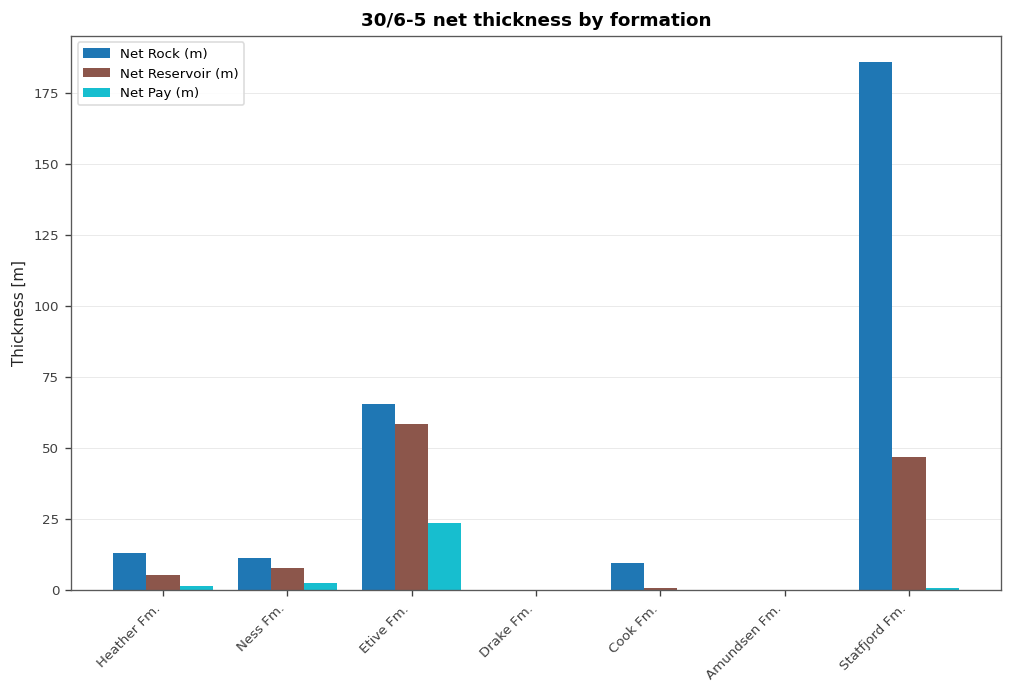

In [31]:
pp.bar_chart(fsum["Formation"], fsum[["Net Rock (m)", "Net Reservoir (m)", "Net Pay (m)"]].to_dict("list"),
             ylabel="Thickness [m]", title="30/6-5 net thickness by formation");

## Pitfalls & parameter choices

- **`pp.plot` draws at once.** The returned `LogViewer` already holds the finished,
  windowed figure (`viewer.fig`, `viewer.axes`). `.show()` displays it, `.save(path)`
  writes png, pdf or svg by the extension, and `.close()` frees memory in loops.
- **`auto` template is curve-driven.** It excludes unavailable curve families.
  `viewer.diagnostics["omitted_tracks"]` distinguishes absent curves from tracks with
  no finite samples in the selected window, and `viewer.diagnostics["optional_tracks"]`
  lists tracks left out unless named in `tracks=`.
- **Pickett/Hingle need water points.** Run them on a **water-bearing** interval; a pure
  hydrocarbon zone has too few 100%-water points and the water-line fit degrades.
- **Flow units need core.** Feed the flow-unit crossplot data where permeability truly
  varies at fixed porosity (core plugs such as `PHIC`/`KH_CORE`); a porosity-derived
  log `PERM` collapses FZI onto one trend.
- **Lithology crossplots need the right curves, and the curves must be right.** On
  30/6-5 the full lithology suite is recorded only in ~2784-3176 m, and even there
  `PEF` reads above 4 b/e in clean quartz sand (barite in the mud). `pp.interpret`
  detects this and solves the minerals without PEF; check its warnings, and check PEF
  against a known clean sand on your own wells.
- **Check default permeability against core.** On HW-3 the default carbonate
  permeability has a median in the thousands of mD, more than two orders of
  magnitude above the file's `PERM_CC`.
- **NMR / FMI panels need the right inputs** (`has_nmr_curves`, a navigation curve).
  The NMR panel renders here from the bundled real Daydream 1 CMR; the FMI panel
  needs an image DLIS - lesson 16 runs it on the real Daydream 1 image.

## Recap

- The **log plot** `pp.plot` (named template or `auto`, with `tracks=`, `curves=`,
  `curve_aliases=` and `curve_styles=`) is your general-purpose multi-track display;
  the **triple combo** is the fast first look.
- The **crossplot family** each answers a specific question: N-D for lithology/gas,
  Pickett/Hingle for `Rw`/`m` and the water line, M-N/MID for matrix mineralogy, Buckles
  for constant-BVW trends, with independent evidence needed for irreducible water.
- **Specialist panels** cover flow units (real 30/6-5 core plugs) and the NMR
  display (real Daydream 1 CMR); the FMI panel renders in lesson 16.
- **Zone flags** summarize where the pay is; `pp.plot(wells, curves=...)`, histogram
  and bar charts compare wells.

## Try it yourself

> **Exercise 1.** Render `pp.plot(geo_result, template="petrophysics", top=2780, bottom=3000)`
> and compare its track layout with `"comprehensive"`. Which curves each template
> emphasises tells you its intended audience.
>
> **Exercise 2.** Re-run the Pickett plot with `m=1.8` and `m=2.2`. How does the assumed
> cementation exponent move the water line, and hence computed `Sw`?
>
> **Exercise 3.** Build a Buckles plot on the clastic well (`geo_result`) over 2780-3000 m. Do the
> points hug a single `PHIE*SW` hyperbola or scatter? What independent evidence would
> distinguish irreducible water from a transition zone?

## What's next

Continue with **18_multiwell_field_study.ipynb**, where these single-well plots scale up:
we interpret the 17-well Costa field in one call, compare the wells' logs, and build a
cross-well comparison table and summary figure.